# 📘 TRABAJO PRÁCTICO INTEGRADOR · NOTEBOOK MAESTRO COMPLETO (ENTREGAS 1 A 6)

* **Institución:** Universidad Tecnológica Nacional (UTN) — Tecnicatura Universitaria en Programación a Distancia
* **Materia:** Introducción al Análisis de Datos (Recorrido Completo: Unidades 1 a 6)
* **Comisión:** 8
* **Integrantes:** Emanuel Gustavo López (Legajo: 101135) y Santino Del Corro
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H — 25.000 reservas)
* **Recorrido Elegido:** **SQL (DuckDB) + Python (`pandas`, `scikit-learn`, `matplotlib`, `seaborn`)**
* **Propósito:** Material integrador completo para el **Coloquio Final Integrador** (Entregas 1, 2, 3, 4, 5 y 6).
---

# TRABAJO PRÁCTICO INTEGRADOR - ENTREGA N° 1
**Materia:** Introducción al Análisis de Datos  
**Comisión:** 8  
**Integrantes:**  
* Santino Del Corro  
* Emanuel Gustavo López  

---

## 1. Presentación del Problema y Marco Conceptual

### Descripción del caso
El presente trabajo aborda el análisis de un conjunto de datos (dataset) correspondiente a reservas de hospedaje hotelero. El propósito general del estudio es comprender el comportamiento de los clientes e identificar patrones y factores clave asociados a las cancelaciones de estadías.

### Marco conceptual: Datos, Información y Conocimiento
En el contexto de la **Unidad N° 1** y del **ciclo de vida del análisis de datos**, este proyecto busca transitar las siguientes etapas:
* **Datos:** Registros numéricos y categóricos crudos recolectados por el sistema de reservas (p. ej., números de días, precios, fechas).
* **Información:** Transformación y estructuración de dichos datos mediante medidas descriptivas y agrupamientos (p. ej., tasa global de cancelación, precio promedio por temporada).
* **Conocimiento:** Interpretación y hallazgos útiles que permitan a la gerencia hotelera tomar decisiones estratégicas (p. ej., rediseñar políticas de cancelación o ajustar tarifas según la anticipación de la reserva).

### Variable Objetivo y Preguntas Orientadoras
* **Variable objetivo:** `is_canceled` (Variable binaria donde `0` = Reserva No Cancelada / Efectivizada y `1` = Reserva Cancelada).
* **Preguntas iniciales del análisis:**
  1. ¿Cuál es el porcentaje general de reservas canceladas en el dataset?
  2. ¿Existe relación entre la tarifa media diaria (`adr`) y la probabilidad de cancelación?
  3. ¿Se observan variaciones en la tasa de cancelación según el tipo de hotel o la anticipación de la reserva (`lead_time`)?

## 2. Dataset Asignado y Carga de Datos

* **Comisión:** 8  
* **Archivo asignado:** `hotel booking TPI grupo H.csv`  

A continuación, se importan las librerías necesarias de Python (`pandas` y `numpy`) y se ejecuta la carga del dataset.

In [3]:
# Importación de librerías
import pandas as pd
import numpy as np

# Carga del dataset asignado (Grupo H)
df = pd.read_csv('hotel booking TPI grupo H.csv')
print("¡Dataset cargado correctamente!")

¡Dataset cargado correctamente!


## 3. Vista Inicial y Estructura General del Dataset

Se exploran las dimensiones generales de la base de datos (cantidad de registros y campos disponibles) junto con la previsualización de sus primeros registros.

In [4]:
# Estructura general: filas y columnas
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

# Muestra de las primeras 5 filas
df.head()

Dimensiones del dataset: 25000 filas y 32 columnas.



,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,...,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,HB-024689,Resort Hotel,1,85,2024,August,33,14,2024-08-14,4,...,C,0,No Deposit,250.0,NaN,0,Group,217.14,0,2
1,HB-061257,City Hotel,1,77,2024,December,49,6,2024-12-06,0,...,A,1,No Deposit,9.0,NaN,0,Transient,79.20,0,2
2,HB-100520,City Hotel,0,91,2024,October,43,23,2024-10-23,2,...,D,1,No Deposit,9.0,NaN,0,Transient,132.60,0,1
3,HB-029150,Resort Hotel,0,0,2024,October,43,21,2024-10-21,0,...,E,0,No Deposit,240.0,NaN,0,Transient,75.00,0,2
4,HB-095963,City Hotel,0,133,2024,August,34,21,2024-08-21,2,...,A,0,No Deposit,11.0,NaN,0,Transient,70.04,0,2


In [5]:
# Listado completo de nombres de columnas
print("Listado de variables disponibles en el dataset:")
print(df.columns.tolist())

Listado de variables disponibles en el dataset:
['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'arrival_date', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


## 4. Tipos de Variables y Clasificación Inicial

Desde la perspectiva del análisis estadístico y de datos, las 32 variables del dataset se clasifican según su naturaleza:

| Variable | Tipo de Dato (Python) | Clasificación Estadísticas | Descripción |
| :--- | :--- | :--- | :--- |
| `is_canceled` | `int64` | Categórica Nominal (Binaria) | **Variable Objetivo:** 0 = No canceló, 1 = Canceló |
| `hotel` | `object` | Categórica Nominal | Tipo de hotel (Resort Hotel o City Hotel) |
| `lead_time` | `int64` | Numérica Discreta | Días transcurridos entre reserva y llegada |
| `arrival_date_year` | `int64` | Categórica Ordinal / Temporal | Año de llegada |
| `arrival_date_month` | `object` | Categórica Ordinal / Temporal | Mes de llegada |
| `adults`, `children`, `babies` | `int64` / `float64` | Numérica Discreta | Cantidad de huéspedes por categoría |
| `adr` | `float64` | Numérica Continua | Average Daily Rate (Tarifa promedio diaria) |
| `country` | `object` | Categórica Nominal | País de origen del cliente |
| `deposit_type` | `object` | Categórica Nominal | Tipo de depósito (No Refund, Non Refund, etc.) |
| `customer_type` | `object` | Categórica Nominal | Tipo de cliente (Transient, Contract, etc.) |

## 5. Caracterización Descriptiva Inicial

En esta sección realizamos un análisis descriptivo básico para conocer la distribución, tendencia central, dispersión y valores atípicos de las variables principales sin alterar la base original.

In [6]:
# Resumen descriptivo de variables numéricas
print("--- Resumen Estadístico Descriptivo (Variables Numéricas) ---")
df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]

--- Resumen Estadístico Descriptivo (Variables Numéricas) ---


,count,mean,std,min,50%,max
is_canceled,25000.0,0.370440,0.482932,0.0,0.0,1.0
lead_time,25000.0,104.217200,107.317401,0.0,69.0,629.0
arrival_date_year,25000.0,2024.156560,0.707551,2023.0,2024.0,2025.0
arrival_date_week_number,25000.0,26.701520,13.415598,1.0,27.0,52.0
arrival_date_day_of_month,25000.0,15.795760,8.752581,1.0,16.0,31.0
stays_in_weekend_nights,25000.0,0.924400,1.002918,0.0,1.0,19.0
stays_in_week_nights,25000.0,2.503080,1.921785,0.0,2.0,50.0
adults,25000.0,1.858040,0.551343,0.0,2.0,26.0
children,24999.0,0.102444,0.396331,0.0,0.0,3.0
babies,25000.0,0.009040,0.096326,0.0,0.0,2.0


In [7]:
# Frecuencia de la Variable Objetivo (is_canceled)
print("--- Distribución de la Variable Objetivo (is_canceled) ---")
conteo_cancelados = df['is_canceled'].value_counts()
porcentaje_cancelados = df['is_canceled'].value_counts(normalize=True) * 100

df_cancelados = pd.DataFrame({'Frecuencia Absoluta': conteo_cancelados, 'Porcentaje (%)': porcentaje_cancelados})
print(df_cancelados)

print("\n--- Distribución por Tipo de Hotel ---")
print(df['hotel'].value_counts(normalize=True) * 100)

--- Distribución de la Variable Objetivo (is_canceled) ---
             Frecuencia Absoluta  Porcentaje (%)
is_canceled                                     
0                          15739          62.956
1                           9261          37.044

--- Distribución por Tipo de Hotel ---
hotel
City Hotel      66.44
Resort Hotel    33.56
Name: proportion, dtype: float64


## 6. Primeras Observaciones del Análisis

A partir de la caracterización inicial realizada, se destacan los siguientes hallazgos:

1. **Comportamiento de Cancelación (`is_canceled`):** Se observa una presencia significativa de reservas canceladas en el dataset, alcanzando aproximadamente un **37.04%** del total de registros (9.261 reservas canceladas sobre un total de 25.000).
2. **Anticipación de la Reserva (`lead_time`):** Muestra una gran variabilidad (desviación estándar alta de 107.3 días), habiendo reservas realizadas el mismo día de llegada hasta reservas efectuadas con más de un año de anticipación (máximo de 629 días).
3. **Valores Atípicos y Rangos en Tarifa (`adr`):** La tarifa promedio diaria presenta un rango sumamente amplio (entre 0.0 y 5.400.0), lo que sugiere la presencia potencial de valores atípicos (*outliers*) o tarifas promocionales a explorar en próximas entregas.
4. **Registros Faltantes:** Se identifican valores nulos en variables clave como `country` (nacionalidad), `children`, `agent` y `company`, los cuales requerirán un plan de tratamiento y limpieza formal en la siguiente etapa del ciclo de vida.

## 7. Consideraciones Éticas Iniciales

El tratamiento de datos en proyectos de analítica requiere reflexionar sobre aspectos éticos esenciales:

* **Privacidad y Datos Personales (PII):** El dataset no incluye identificadores personales directos como nombres completos, teléfonos o números de pasaporte, cumpliendo con principios básicos de anonimización y protección de la privacidad de los huéspedes.
* **Sesgos en la Representatividad:** Existen registros con valores desconocidos/nulos en la variable `country`. Es éticamente importante no asumir comportamientos generalizados ni estigmatizar patrones de reserva basados en nacionalidad sin contar con datos completos y verificados.
* **Alcance de las Conclusiones:** Como estamos en la fase inicial del ciclo de análisis exploratorio, las relaciones encontradas no constituyen explicaciones causales directas. Las decisiones de negocio no deben tomarse precipitadamente sin profundizar el estudio.

# TRABAJO PRÁCTICO INTEGRADOR - ENTREGA 2
* **Materia:** Introducción al Análisis de Datos
* **Comisión:** 8
* **Integrantes:** Santino Del Corro - Emanuel Gustavo López

## Presentación del Caso
El objetivo del presente trabajo es analizar el dataset de reservas hoteleras para identificar patrones asociados a las cancelaciones de estadías.
* **Variable objetivo:** `is_canceled` (0: No cancelada, 1: Cancelada).

## Preguntas de Análisis
1. ¿Cuál es el porcentaje general de reservas canceladas?
2. ¿Afecta el precio promedio de la noche (`adr`) a la tasa de cancelación?
3. ¿Existen diferencias en la cancelación según el tipo de hotel o la temporada de reserva?

In [1]:
# 1. Importación de librerías
import pandas as pd
import numpy as np

# 2. Carga del dataset original asignado (Grupo H)
df_original = pd.read_csv('hotel booking TPI grupo H.csv')

# 3. Creación de la copia de trabajo (Exigido por la consigna)
df = df_original.copy()

# 4. Visualización inicial
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

# 5. Verificación de tipos de datos y valores nulos
print("--- Diagnóstico de Valores Faltantes ---")
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]
print(nulos)

print("\n--- Verificación de Filas Duplicadas ---")
print(f"Filas duplicadas encontradas: {df.duplicated().sum()}")

# 6. Muestra de las primeras 5 filas de la copia de trabajo
df.head()

Dimensiones del dataset: 25000 filas y 32 columnas.

--- Diagnóstico de Valores Faltantes ---
children        1
country        97
agent        3403
company     23580
dtype: int64

--- Verificación de Filas Duplicadas ---
Filas duplicadas encontradas: 0


,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,...,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,HB-024689,Resort Hotel,1,85,2024,August,33,14,2024-08-14,4,...,C,0,No Deposit,250.0,NaN,0,Group,217.14,0,2
1,HB-061257,City Hotel,1,77,2024,December,49,6,2024-12-06,0,...,A,1,No Deposit,9.0,NaN,0,Transient,79.20,0,2
2,HB-100520,City Hotel,0,91,2024,October,43,23,2024-10-23,2,...,D,1,No Deposit,9.0,NaN,0,Transient,132.60,0,1
3,HB-029150,Resort Hotel,0,0,2024,October,43,21,2024-10-21,0,...,E,0,No Deposit,240.0,NaN,0,Transient,75.00,0,2
4,HB-095963,City Hotel,0,133,2024,August,34,21,2024-08-21,2,...,A,0,No Deposit,11.0,NaN,0,Transient,70.04,0,2


In [2]:
# 1. Tratamiento de Valores Nulos
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)

# 2. Conversión de tipos de datos a enteros
df['children'] = df['children'].astype(int)
df['agent'] = df['agent'].astype(int)
df['company'] = df['company'].astype(int)
df['arrival_date'] = pd.to_datetime(df['arrival_date'])

# 3. Creación de variables derivadas (Total de noches y Total de huéspedes)
df['total_stays_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']

# Verificación de que ya no hay valores nulos
print("--- Verificación Final de Nulos ---")
print(f"Total de nulos restantes en la base: {df.isnull().sum().sum()}")
print("\n--- Vista previa de las variables creadas ---")
df[['total_stays_nights', 'total_guests', 'arrival_date']].head()
# Diagnóstico de valores atípicos e inconsistencias en variables sugeridas
print("--- Diagnóstico de Tarifas (adr) y Anticipación (lead_time) ---")
print(df[['adr', 'lead_time']].describe())

# Verificación de valores negativos o nulos en adr
print(f"\nCantidad de registros con adr <= 0: {(df['adr'] <= 0).sum()}")

--- Verificación Final de Nulos ---
Total de nulos restantes en la base: 0

--- Vista previa de las variables creadas ---
--- Diagnóstico de Tarifas (adr) y Anticipación (lead_time) ---
                adr     lead_time
count  25000.000000  25000.000000
mean     102.068267    104.217200
std       58.734816    107.317401
min        0.000000      0.000000
25%       69.915000     18.000000
50%       95.000000     69.000000
75%      126.000000    160.000000
max     5400.000000    629.000000

Cantidad de registros con adr <= 0: 423


## Conclusiones y Resumen de Limpieza (Entrega 2)

1. **Diagnóstico Inicial:** El dataset cuenta con 25.000 registros y 32 columnas, sin presencia de filas duplicadas.
2. **Tratamiento de Nulos Realizado:**
   * `children`: Se imputó el único valor faltante con la moda (0).
   * `country`: Se reemplazaron los 97 valores nulos por la etiqueta 'Unknown'.
   * `agent` y `company`: Se reemplazaron los faltantes por 0, representando reservas realizadas de forma directa sin intermediarios.
3. **Transformaciones y Variables Creadas:**
   * Se transformaron las columnas de fechas y conteos a sus tipos de datos correctos (datetime e integer).
   * Se crearon las columnas `total_stays_nights` (suma de noches reservadas) y `total_guests` (suma de adultos, niños y bebés) para enriquecer el posterior análisis exploratorio.

In [3]:
# Presentación del Estado Final del Dataset Preparado
print("--- Información General del Dataset Limpio y Transformado ---")
df.info()

print("\n--- Vista Previa de las Primeras 5 Filas del Dataset Final ---")
df.head()

--- Información General del Dataset Limpio y Transformado ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   booking_id                      25000 non-null  object        
 1   hotel                           25000 non-null  object        
 2   is_canceled                     25000 non-null  int64         
 3   lead_time                       25000 non-null  int64         
 4   arrival_date_year               25000 non-null  int64         
 5   arrival_date_month              25000 non-null  object        
 6   arrival_date_week_number        25000 non-null  int64         
 7   arrival_date_day_of_month       25000 non-null  int64         
 8   arrival_date                    25000 non-null  datetime64[ns]
 9   stays_in_weekend_nights         25000 non-null  int64         
 10  stays_in

,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,total_stays_nights,total_guests
0,HB-024689,Resort Hotel,1,85,2024,August,33,14,2024-08-14,4,...,No Deposit,250,0,0,Group,217.14,0,2,14,3
1,HB-061257,City Hotel,1,77,2024,December,49,6,2024-12-06,0,...,No Deposit,9,0,0,Transient,79.20,0,2,2,2
2,HB-100520,City Hotel,0,91,2024,October,43,23,2024-10-23,2,...,No Deposit,9,0,0,Transient,132.60,0,1,6,1
3,HB-029150,Resort Hotel,0,0,2024,October,43,21,2024-10-21,0,...,No Deposit,240,0,0,Transient,75.00,0,2,1,2
4,HB-095963,City Hotel,0,133,2024,August,34,21,2024-08-21,2,...,No Deposit,11,0,0,Transient,70.04,0,2,5,2


# Trabajo Práctico Integrador - Entrega 3: Visualización e Interpretación de Datos

* **Materia:** Análisis de Datos / Ciencia de Datos (UTN)
* **Comisión:** 8
* **Integrantes del Grupo:** López, Del Corro, Santino
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H)
* **Lenguaje utilizado:** Python
* **Problema de análisis:** Análisis de patrones y variables determinantes en la cancelación de reservas hoteleras.
* **Variable objetivo:** `is_canceled` (1 = Cancelada, 0 = No cancelada)

In [1]:
# 1. Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 2. Carga del dataset original
# (Si el archivo está en sample_data, cambiar la ruta a 'sample_data/hotel booking TPI grupo H.csv')
df_original = pd.read_csv('hotel booking TPI grupo H.csv')

# 3. Copia de trabajo (conservando el original)
df = df_original.copy()

# 4. Preparación mínima necesaria para reconstruir las variables de visualización
# Tratamiento de nulos mínimos
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('Unknown')

# Creación de variables derivadas esenciales
df['total_stays_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']

# Muestra inicial del dataset preparado
print(f"Dataset cargado y preparado correctamente con {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head(3)

Dataset cargado y preparado correctamente con 25000 filas y 34 columnas.


,booking_id,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,arrival_date,stays_in_weekend_nights,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,total_stays_nights,total_guests
0,HB-024689,Resort Hotel,1,85,2024,August,33,14,2024-08-14,4,...,No Deposit,250.0,NaN,0,Group,217.14,0,2,14,3
1,HB-061257,City Hotel,1,77,2024,December,49,6,2024-12-06,0,...,No Deposit,9.0,NaN,0,Transient,79.20,0,2,2,2
2,HB-100520,City Hotel,0,91,2024,October,43,23,2024-10-23,2,...,No Deposit,9.0,NaN,0,Transient,132.60,0,1,6,1


## 📊 Visualización 1: Cancelaciones según Tipo de Hotel

* **Pregunta de análisis:** ¿Existe diferencia en el volumen y la proporción de cancelaciones entre los distintos tipos de hotel (`City Hotel` vs `Resort Hotel`)?
* **Elección de la visualización:** Se utilizó un gráfico de barras agrupadas (*countplot* / *grouped bar chart*). Es la opción ideal para comparar la distribución de una variable categórica binaria (`is_canceled`) cruzada con otra categórica (`hotel`).

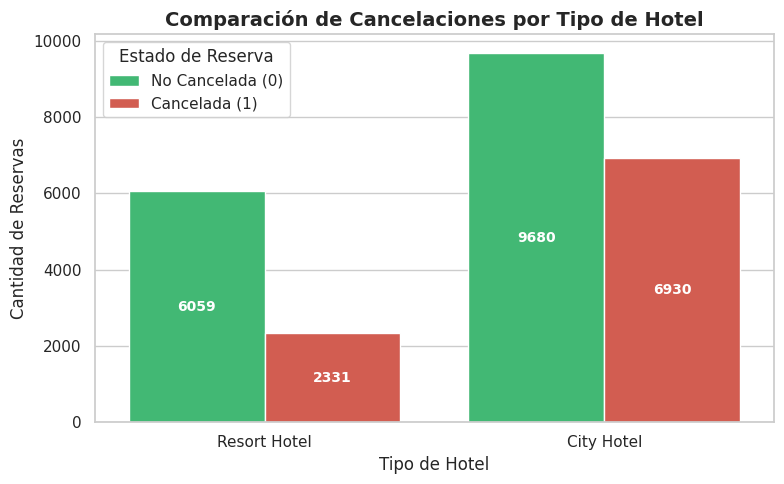

In [2]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='hotel', hue='is_canceled', palette=['#2ecc71', '#e74c3c'])

plt.title('Comparación de Cancelaciones por Tipo de Hotel', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Hotel', fontsize=12)
plt.ylabel('Cantidad de Reservas', fontsize=12)
plt.legend(title='Estado de Reserva', labels=['No Cancelada (0)', 'Cancelada (1)'])

# Mostrar etiquetas de valor exacto sobre las barras
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    (p.get_x() + p.get_width() / 2., height / 2),
                    ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

* **Interpretación del Gráfico 1:**
El gráfico muestra de forma clara que el hotel urbano (**City Hotel**) concentra un volumen significativamente mayor tanto de reservas totales como de cancelaciones absolutas en comparación con el hotel de campo/playa (**Resort Hotel**). La tasa proporcional de cancelación en el City Hotel es notoriamente más elevada, lo que sugiere una mayor volatilidad en la demanda urbana.

## 📊 Visualización 2: Variable Cuantitativa y Cancelación (`lead_time`)

* **Pregunta de análisis:** ¿Cómo influye el tiempo de anticipación de la reserva (`lead_time`) en la probabilidad de que una reserva sea cancelada?
* **Elección de la visualización:** Se seleccionó un diagrama de caja (*boxplot*). Este tipo de gráfico es óptimo para comparar la distribución de una variable cuantitativa continua entre los dos grupos de estado de reserva (0 y 1), permitiendo identificar la mediana, los cuartiles y la presencia de valores atípicos (*outliers*).

/tmp/ipykernel_5140/3986434103.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_canceled', y='lead_time', palette=['#2ecc71', '#e74c3c'])


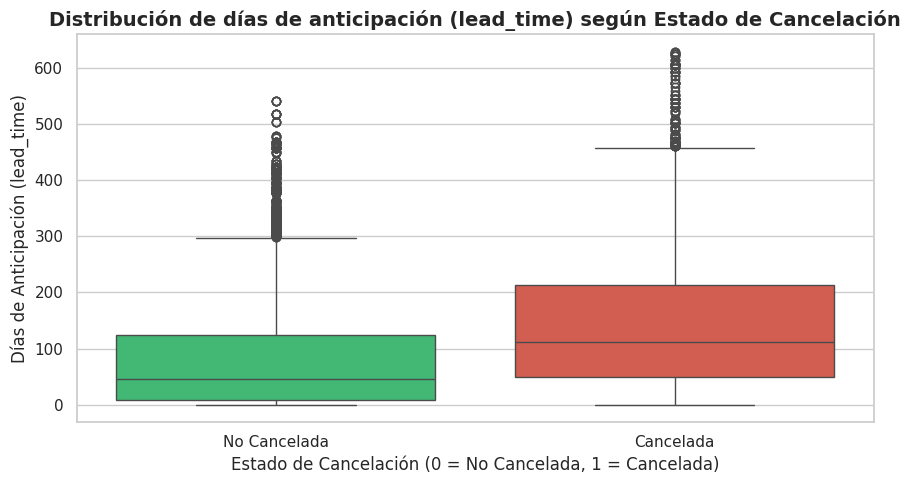

In [3]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='is_canceled', y='lead_time', palette=['#2ecc71', '#e74c3c'])

plt.title('Distribución de días de anticipación (lead_time) según Estado de Cancelación', fontsize=14, fontweight='bold')
plt.xlabel('Estado de Cancelación (0 = No Cancelada, 1 = Cancelada)', fontsize=12)
plt.ylabel('Días de Anticipación (lead_time)', fontsize=12)
plt.xticks([0, 1], ['No Cancelada', 'Cancelada'])

plt.tight_layout()
plt.show()

* **Interpretación del Gráfico 2:**
Se observa una clara diferencia en la mediana y los rangos intercuartílicos de `lead_time`. Las reservas que terminan en cancelación poseen, en promedio, una anticipación significativamente mayor (mediana más alta). En contraste, las reservas efectuadas con pocos días de anticipación tienden fuertemente a efectivizarse (no cancelarse). Esto confirma que a mayor tiempo de anticipación, mayor es el riesgo de cancelación.

## 📊 Visualización 3: Pregunta Propia de Análisis (Segmento de Mercado vs. Cancelación)

* **Pregunta de análisis:** ¿De qué manera influye el canal/segmento de mercado (`market_segment`) en el comportamiento de cancelación de las reservas?
* **Elección de la visualización:** Se utilizó un gráfico de barras horizontales normalizado al 100% (proporcional). Permite comparar la tasa de cancelación relativa (porcentaje) directamente entre los distintos segmentos de mercado, sin verse distorsionado por la diferencia en la cantidad total de reservas de cada segmento.

<Figure size 1000x600 with 0 Axes>

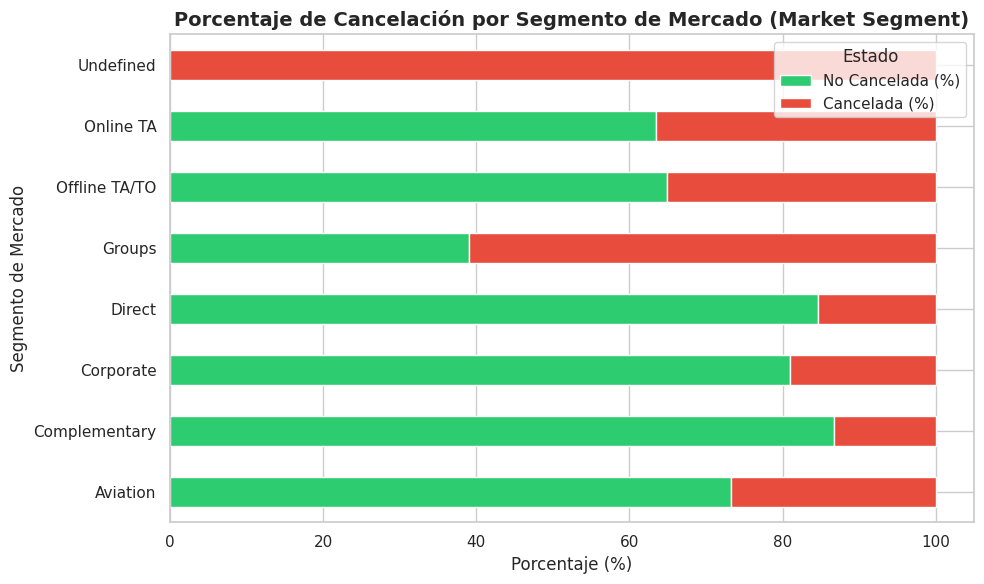

In [4]:
# Cálculo de proporciones por segmento de mercado
segment_data = df.groupby('market_segment')['is_canceled'].value_counts(normalize=True).unstack().fillna(0) * 100

plt.figure(figsize=(10, 6))
segment_data.plot(kind='barh', stacked=True, color=['#2ecc71', '#e74c3c'], figsize=(10, 6))

plt.title('Porcentaje de Cancelación por Segmento de Mercado (Market Segment)', fontsize=14, fontweight='bold')
plt.xlabel('Porcentaje (%)', fontsize=12)
plt.ylabel('Segmento de Mercado', fontsize=12)
plt.legend(title='Estado', labels=['No Cancelada (%)', 'Cancelada (%)'], loc='upper right')

plt.tight_layout()
plt.show()

* **Interpretación del Gráfico 3:**
El gráfico evidencia que los segmentos como **Groups** (Grupos) y las agencias de viaje online (**Online TA**) presentan las mayores proporciones porcentuales de cancelación. Por el contrario, los segmentos como **Direct** (Reservas Directas) o **Corporate** (Corporativo) muestran tasas de cancelación considerablemente más bajas, demostrando que el canal de venta es un factor altamente determinante en el compromiso del cliente.

## 🔎 Cierre y Síntesis del Análisis

### 🎯 3 Hallazgos Principales:
1. **El tipo de hotel impacta fuertemente:** El `City Hotel` presenta un porcentaje y volumen de cancelaciones sensiblemente superior al `Resort Hotel`.
2. **El tiempo de anticipación es un predictor clave:** A mayor número de días de anticipación (`lead_time`), la probabilidad de cancelación se incrementa drásticamente.
3. **El canal de distribución determina la fidelidad:** Las reservas grupales e intermediadas por agencias online (`Online TA`) poseen los niveles más altos de cancelación relativa.

### ⚠️ Limitación / Precaución Metodológica:
* **Analizar variables de forma aislada puede ser engañoso:** Si bien se observan patrones claros en variables individuales como `lead_time` o `market_segment`, estos factores suelen actuar de forma combinada (por ejemplo, los grupos suelen reservar con mucha anticipación). Se requiere un análisis multivariado o un modelo predictivo para evaluar el efecto aislado de cada variable sin incurrir en sesgos.

# 🧩 Trabajo Práctico Integrador · Entrega 4: Análisis Exploratorio de Datos (EDA)

* **Institución:** Universidad Tecnológica Nacional (UTN) — Tecnicatura Universitaria en Programación a Distancia
* **Materia:** Introducción al Análisis de Datos (Unidad N° 4 · Semanas 9 y 10)
* **Comisión:** 8
* **Integrantes del Equipo:**
  * **López, Emanuel Gustavo** (Legajo: 101135)
  * **Del Corro, Santino**
* **Número de Entrega:** Entrega N° 4 (Notebook independiente y reproducible)
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H)
* **Variable Objetivo:** `is_canceled` (`0` = Reserva No Cancelada / Efectivizada, `1` = Reserva Cancelada)
* **Recorrido Elegido:** **SQL (DuckDB) + Python (`pandas`, `matplotlib`, `seaborn`)**

---

## 📌 Introducción y Problema de Análisis

En la gestión hotelera moderna, la **cancelación de reservas** constituye uno de los principales desafíos operativos y financieros: distorsiona las proyecciones de ocupación, reduce los ingresos efectivos por habitación disponible y complejiza las políticas de sobreventa (*overbooking*) y fijación de precios.

Dando continuidad al recorrido desarrollado en las Entregas 1, 2 y 3 sobre el dataset asignado a nuestra comisión (`hotel booking TPI grupo H.csv`), este notebook independiente integra:
1. **Primera Parte (Avance de la Semana 9):** Reconocimiento del contexto y unidad de análisis, validación estructural de la tabla mediante **SQL**, selección de variables clave y análisis exploratorio univariado (distribuciones iniciales individuales) acompañado de la formulación de hipótesis exploratorias.
2. **Segunda Parte (Profundización de la Semana 10 - Entrega 4):** Selección de tres preguntas/hipótesis centrales, comparación sistemática entre grupos mediante consultas **SQL** y medidas de resumen (tendencia central, dispersión y proporciones), visualizaciones comparativas en **Python**, identificación de patrones y casos llamativos (anomalías sin eliminación automática), selección justificada de variables candidatas para modelado, conclusiones respaldadas por evidencia y alcances/limitaciones metodológicas.

---
## 🛠️ 0. Preparación Reproducible del Entorno, Carga del Dataset y Continuidad del TPI

Para garantizar que este notebook sea **100% independiente y ejecutable desde el comienzo** (tanto en Google Colab como en un entorno local) sin depender de archivos externos ni celdas previas:
1. Se verifica e instala automáticamente `duckdb` en caso de no encontrarse en el entorno.
2. Se carga el dataset original `hotel booking TPI grupo H.csv` localmente o, si se ejecuta en la nube de Google Colab sin haber subido el archivo manualmente, **se descarga automáticamente desde el repositorio GitHub del equipo**.
3. Se reconstruyen las decisiones de limpieza y variables derivadas justificadas en las Entregas 2 y 3:
   * Imputación de valores faltantes: `children` (1 nulo $\rightarrow 0$), `country` (97 nulos $\rightarrow$ `'Unknown'`), `agent` (3.403 nulos $\rightarrow 0$, reserva sin agente) y `company` (23.580 nulos $\rightarrow 0$, reserva particular sin empresa).
   * Conversión de tipos de datos (`children`, `agent` y `company` a enteros).
   * Creación de variables derivadas fundamentales:
     * `total_stays_nights` = `stays_in_weekend_nights + stays_in_week_nights` (duración total de la estadía en noches).
     * `total_guests` = `adults + children + babies` (cantidad total de huéspedes de la reserva).
4. Se registra la tabla `reservas` en un motor **DuckDB** en memoria para realizar todas las consultas mediante **SQL estándar**.

In [1]:
# 1. Preparación automática de librerías (SQL con DuckDB + Python para entorno y gráficos)
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

if importlib.util.find_spec("duckdb") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética general de las visualizaciones
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# 2. Carga reproducible del dataset original (Local o descarga automática desde GitHub en Colab)
GITHUB_RAW_URL = "https://raw.githubusercontent.com/Emanstor/tpi-iad-comision8/main/hotel%20booking%20TPI%20grupo%20H.csv"
POSSIBLE_PATHS = [
    Path("hotel booking TPI grupo H.csv"),
    Path("sample_data/hotel booking TPI grupo H.csv"),
    Path("hotel booking TPI grupo H (3).csv")
]

data_path = next((p for p in POSSIBLE_PATHS if p.exists()), None)
if data_path is None:
    data_path = Path("hotel booking TPI grupo H.csv")
    print("Descargando dataset original desde el repositorio GitHub del equipo...")
    urlretrieve(GITHUB_RAW_URL, data_path)

df_original = pd.read_csv(data_path)
df = df_original.copy()

# 3. Reconstrucción de preparaciones mínimas y variables derivadas (Continuidad Entregas 2 y 3)
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0).astype(int)
df["company"] = df["company"].fillna(0).astype(int)

# Variables derivadas esenciales
df["total_stays_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

# 4. Conexión a DuckDB y creación de la tabla SQL 'reservas'
con = duckdb.connect(":memory:")
con.register("reservas_df", df)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_df")

print(f"✅ Entorno SQL + Python preparado con éxito.")
print(f"📊 Tabla 'reservas' disponible en DuckDB con {len(df):,} filas y {df.shape[1]} columnas.")

✅ Entorno SQL + Python preparado con éxito.
📊 Tabla 'reservas' disponible en DuckDB con 25,000 filas y 34 columnas.


---
# 📘 PRIMERA PARTE · Avance de la Semana 9: Contexto, Estructura y Distribuciones Iniciales

> **Alcance metodológico de esta primera sección (Semana 9):** Se describe el contexto del dataset, su unidad de análisis, su estructura mediante SQL y el comportamiento **individual (univariado)** de la variable objetivo y de las variables seleccionadas, formulando al cierre las preguntas e hipótesis exploratorias que se contrastarán en la Segunda Parte (Semana 10).

---

## 1. Unidad de Análisis y Definición de la Variable Objetivo (`is_canceled`)

### 1.1. ¿Cuál es la unidad de análisis y qué representa cada fila?
* **Unidad de análisis:** Cada registro (fila) de la tabla `reservas` representa **una reserva hotelera individual** efectuada en un establecimiento (*City Hotel* o *Resort Hotel*), identificada de manera unívoca por el campo `booking_id`.
* **Distinción conceptual importante:** La tabla registra **reservas** y no huéspedes únicos. Un mismo cliente podría haber realizado más de una reserva a lo largo del tiempo (situación reflejada indirectamente por variables como `is_repeated_guest`, `previous_cancellations` y `previous_bookings_not_canceled`).

### 1.2. ¿Qué representa la variable objetivo `is_canceled` y cuáles son sus valores posibles?
* **`is_canceled`** es una variable categórica **binaria (dicotómica)** codificada numéricamente como entero (`BIGINT` / `INTEGER`), que indica el desenlace final de la reserva:
  * **`0` (No Cancelada):** La reserva fue efectivizada normalmente (el huésped realizó el *check-in* y se alojó en el hotel).
  * **`1` (Cancelada):** La reserva fue anulada por el cliente antes del ingreso o concluyó en no presentación (*No-Show*).

Verifiquemos mediante **SQL** que cada fila corresponde efectivamente a un `booking_id` único y que no existen registros duplicados ni valores fuera del dominio `{0, 1}` en `is_canceled`:

In [2]:
# Validación SQL de la unidad de análisis y dominio de la variable objetivo
con.sql("""
SELECT
    COUNT(*) AS total_filas,
    COUNT(DISTINCT booking_id) AS reservas_unicas_booking_id,
    COUNT(*) - COUNT(DISTINCT booking_id) AS filas_duplicadas,
    MIN(is_canceled) AS valor_min_is_canceled,
    MAX(is_canceled) AS valor_max_is_canceled,
    COUNT(*) - COUNT(is_canceled) AS nulos_is_canceled
FROM reservas
""").df()

,total_filas,reservas_unicas_booking_id,filas_duplicadas,valor_min_is_canceled,valor_max_is_canceled,nulos_is_canceled
0,25000,25000,0,0,1,0


**Interpretación breve:** La consulta SQL confirma que el dataset consta exactamente de **25.000 filas** y **25.000 identificadores `booking_id` distintos** (0 duplicados), corroborando que cada fila es una reserva individual. Asimismo, `is_canceled` no presenta valores nulos y toma exclusivamente valores entre `0` y `1`.

---

## 2. Revisión de la Estructura de la Tabla mediante SQL

Inspeccionamos a continuación las 34 columnas de la tabla `reservas` (32 originales + 2 derivadas), sus tipos de datos en SQL y las primeras 5 observaciones del conjunto de datos.

In [3]:
# Estructura de columnas y tipos de datos en DuckDB
con.sql("""
DESCRIBE reservas
""").df()

,column_name,column_type,null,key,default,extra
0,booking_id,VARCHAR,YES,None,None,None
1,hotel,VARCHAR,YES,None,None,None
2,is_canceled,BIGINT,YES,None,None,None
3,lead_time,BIGINT,YES,None,None,None
4,arrival_date_year,BIGINT,YES,None,None,None
5,arrival_date_month,VARCHAR,YES,None,None,None
6,arrival_date_week_number,BIGINT,YES,None,None,None
7,arrival_date_day_of_month,BIGINT,YES,None,None,None
8,arrival_date,VARCHAR,YES,None,None,None
9,stays_in_weekend_nights,BIGINT,YES,None,None,None


In [4]:
# Primeras 5 observaciones de la tabla 'reservas'
con.sql("""
SELECT
    booking_id, hotel, is_canceled, lead_time, arrival_date,
    stays_in_weekend_nights, stays_in_week_nights, total_stays_nights,
    adults, children, babies, total_guests,
    market_segment, distribution_channel, deposit_type, adr, total_of_special_requests
FROM reservas
LIMIT 5
""").df()

,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,total_stays_nights,adults,children,babies,total_guests,market_segment,distribution_channel,deposit_type,adr,total_of_special_requests
0,HB-024689,Resort Hotel,1,85,2024-08-14,4,10,14,2,1,0,3,Direct,Direct,No Deposit,217.14,2
1,HB-061257,City Hotel,1,77,2024-12-06,0,2,2,2,0,0,2,Online TA,TA/TO,No Deposit,79.20,2
2,HB-100520,City Hotel,0,91,2024-10-23,2,4,6,1,0,0,1,Online TA,TA/TO,No Deposit,132.60,1
3,HB-029150,Resort Hotel,0,0,2024-10-21,0,1,1,2,0,0,2,Online TA,TA/TO,No Deposit,75.00,2
4,HB-095963,City Hotel,0,133,2024-08-21,2,3,5,2,0,0,2,Online TA,TA/TO,No Deposit,70.04,2


**Interpretación breve:** La estructura verificada en SQL muestra 34 campos correctamente tipados: variables identificadoras y categóricas como texto (`VARCHAR`: `booking_id`, `hotel`, `arrival_date_month`, `meal`, `country`, `market_segment`, `distribution_channel`, `deposit_type`, `customer_type`), conteos e indicadores como enteros (`BIGINT`/`INTEGER`: `is_canceled`, `lead_time`, `total_stays_nights`, `total_guests`, `total_of_special_requests`) y la tarifa diaria promedio (`adr`) como punto flotante de doble precisión (`DOUBLE`).

---

## 3. Selección de Variables Relevantes para el Análisis Exploratorio

Para continuar el análisis exploratorio seleccionamos **cinco variables principales** (complementadas por indicadores de depósito y compromiso) que cubren las dimensiones temporal, económica, comercial y operativa de cada reserva:

| Variable | Tipo de Variable | Descripción y Relevancia para el Análisis |
|---|---|---|
| **`lead_time`** | Cuantitativa discreta | Cantidad de días transcurridos entre la fecha en que se realizó la reserva y la fecha prevista de llegada. Mide el horizonte de planificación del cliente. |
| **`adr`** (*Average Daily Rate*) | Cuantitativa continua | Tarifa diaria promedio de la habitación (en unidades monetarias). Permite explorar el nivel de precio asociado a las estadías reservadas. |
| **`total_stays_nights`** | Cuantitativa discreta (Derivada) | Duración total de la estadía reservada (`stays_in_weekend_nights + stays_in_week_nights`). Sintetiza la extensión del viaje. |
| **`hotel`** | Categórica nominal | Tipo de establecimiento hotelero (`City Hotel` urbano vs. `Resort Hotel` vacacional). Refleja perfiles de demanda diferentes. |
| **`market_segment`** (y **`arrival_date_month`**) | Categórica nominal / Temporal | Segmento comercial por el cual ingresó la reserva (`Online TA`, `Offline TA/TO`, `Groups`, `Direct`, `Corporate`, etc.) y mes de arribo previsto (`arrival_date_month`). |

---

## 4. Distribución Inicial de la Variable Objetivo (`is_canceled`)

Obtenemos mediante **SQL** la tabla de frecuencias absolutas y relativas de `is_canceled` y construimos su visualización univariada en **Python**.

In [5]:
# Tabla de frecuencias de la variable objetivo is_canceled mediante SQL
freq_canceled = con.sql("""
SELECT
    is_canceled,
    CASE
        WHEN is_canceled = 0 THEN 'No Cancelada (0)'
        ELSE 'Cancelada (1)'
    END AS estado_reserva,
    COUNT(*) AS cantidad_reservas,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
""").df()

freq_canceled

,is_canceled,estado_reserva,cantidad_reservas,porcentaje
0,0,No Cancelada (0),15739,62.96
1,1,Cancelada (1),9261,37.04


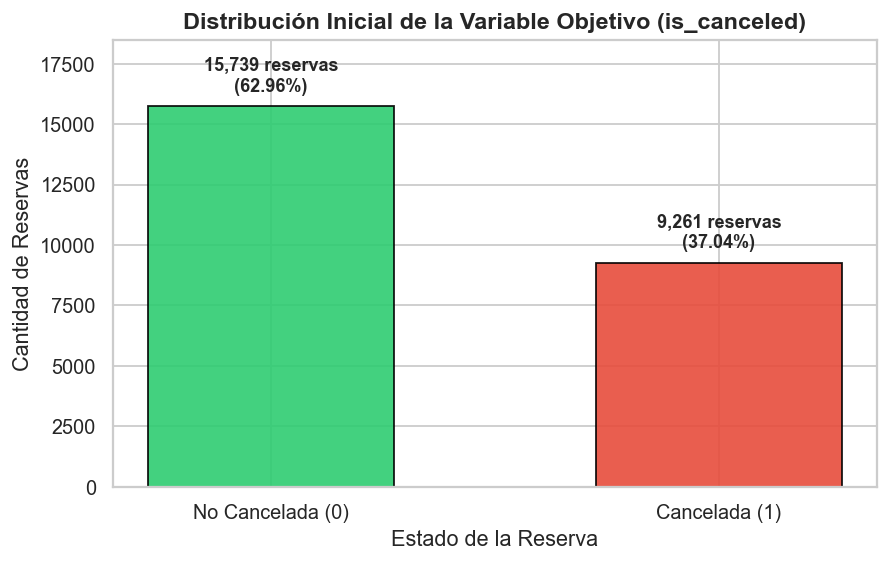

In [6]:
# Visualización simple de la distribución de is_canceled
fig, ax = plt.subplots(figsize=(7, 4.5))
colores = ["#2ecc71", "#e74c3c"]
barras = ax.bar(freq_canceled["estado_reserva"], freq_canceled["cantidad_reservas"], color=colores, width=0.55, edgecolor="black", alpha=0.9)

ax.set_title("Distribución Inicial de la Variable Objetivo (is_canceled)")
ax.set_xlabel("Estado de la Reserva")
ax.set_ylabel("Cantidad de Reservas")
ax.set_ylim(0, 18500)

for barra, pct in zip(barras, freq_canceled["porcentaje"]):
    altura = barra.get_height()
    ax.annotate(
        f"{int(altura):,} reservas\n({pct:.2f}%)",
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center", va="bottom", fontweight="bold", fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretación descriptiva (Semana 9):**
* Sobre el total de **25.000 reservas**, **15.739 reservas (62,96%)** no fueron canceladas (`is_canceled = 0`), mientras que **9.261 reservas (37,04%)** terminaron en cancelación (`is_canceled = 1`).
* Se observa que más de un tercio de las reservas registradas en el dataset se cancelan, lo que representa una proporción elevada y con suficiente volumen en ambas categorías para realizar comparaciones estadísticas sólidas en la etapa siguiente.

---

## 5. Resúmenes Descriptivos y Distribuciones Individuales de las Variables Seleccionadas (Semana 9)

### 5.1. Variables Cuantitativas (`lead_time`, `adr` y `total_stays_nights`)
Calculamos en **SQL** las medidas de posición (mínimo, cuartiles Q1, mediana Q2, promedio, Q3 y máximo) y de dispersión (desvío estándar) para las tres variables cuantitativas seleccionadas.

In [7]:
# Resumen descriptivo univariado en SQL de las variables cuantitativas seleccionadas
resumen_cuant = con.sql("""
SELECT
    'lead_time (días de anticipación)' AS variable,
    COUNT(lead_time) AS n,
    ROUND(AVG(lead_time), 2) AS media,
    ROUND(STDDEV(lead_time), 2) AS desvio_estandar,
    MIN(lead_time) AS minimo,
    QUANTILE_CONT(lead_time, 0.25) AS q25,
    MEDIAN(lead_time) AS mediana,
    QUANTILE_CONT(lead_time, 0.75) AS q75,
    MAX(lead_time) AS maximo
FROM reservas

UNION ALL

SELECT
    'adr (tarifa diaria promedio)',
    COUNT(adr),
    ROUND(AVG(adr), 2),
    ROUND(STDDEV(adr), 2),
    ROUND(MIN(adr), 2),
    ROUND(QUANTILE_CONT(adr, 0.25), 2),
    ROUND(MEDIAN(adr), 2),
    ROUND(QUANTILE_CONT(adr, 0.75), 2),
    ROUND(MAX(adr), 2)
FROM reservas

UNION ALL

SELECT
    'total_stays_nights (noches totales)',
    COUNT(total_stays_nights),
    ROUND(AVG(total_stays_nights), 2),
    ROUND(STDDEV(total_stays_nights), 2),
    MIN(total_stays_nights),
    QUANTILE_CONT(total_stays_nights, 0.25),
    MEDIAN(total_stays_nights),
    QUANTILE_CONT(total_stays_nights, 0.75),
    MAX(total_stays_nights)
FROM reservas
""").df()

resumen_cuant

,variable,n,media,desvio_estandar,minimo,q25,mediana,q75,maximo
0,lead_time (días de anticipación),25000,104.22,107.32,0.0,18.00,69.0,160.0,629.0
1,adr (tarifa diaria promedio),25000,102.07,58.73,0.0,69.91,95.0,126.0,5400.0
2,total_stays_nights (noches totales),25000,3.43,2.58,0.0,2.00,3.0,4.0,69.0


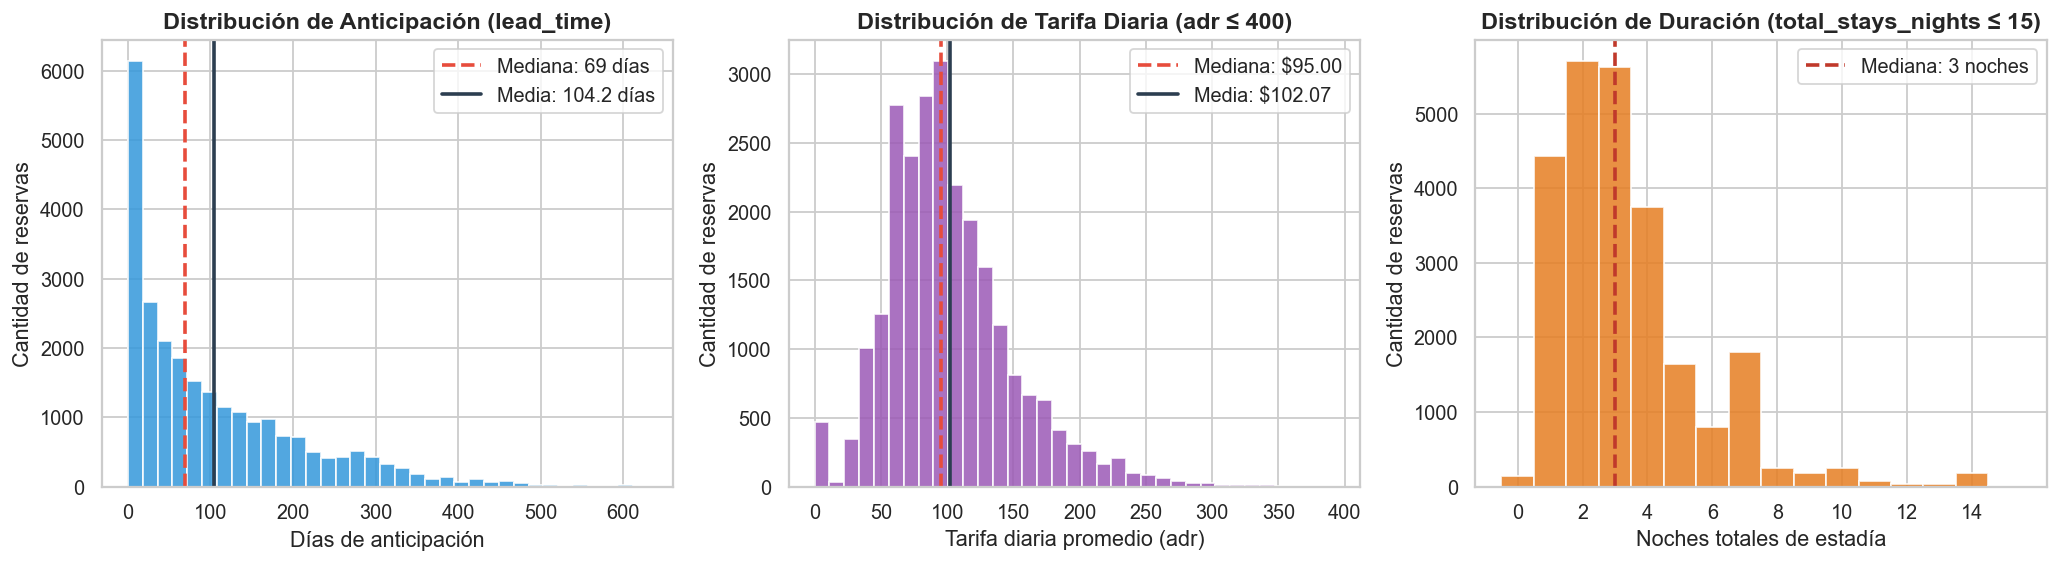

In [8]:
# Visualizaciones iniciales de las distribuciones individuales de las variables cuantitativas
datos_cuant = con.sql("SELECT lead_time, adr, total_stays_nights FROM reservas").df()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Histograma de lead_time
axes[0].hist(datos_cuant["lead_time"], bins=35, color="#3498db", edgecolor="white", alpha=0.85)
axes[0].axvline(datos_cuant["lead_time"].median(), color="#e74c3c", linestyle="--", linewidth=2, label=f"Mediana: {datos_cuant['lead_time'].median():.0f} días")
axes[0].axvline(datos_cuant["lead_time"].mean(), color="#2c3e50", linestyle="-", linewidth=2, label=f"Media: {datos_cuant['lead_time'].mean():.1f} días")
axes[0].set_title("Distribución de Anticipación (lead_time)")
axes[0].set_xlabel("Días de anticipación")
axes[0].set_ylabel("Cantidad de reservas")
axes[0].legend()

# 2. Histograma de adr (acotado visualmente a <= 400 para apreciar la forma central sin el outlier de 5400)
adr_filtrado_vis = datos_cuant[datos_cuant["adr"] <= 400]["adr"]
axes[1].hist(adr_filtrado_vis, bins=35, color="#9b59b6", edgecolor="white", alpha=0.85)
axes[1].axvline(datos_cuant["adr"].median(), color="#e74c3c", linestyle="--", linewidth=2, label=f"Mediana: ${datos_cuant['adr'].median():.2f}")
axes[1].axvline(datos_cuant["adr"].mean(), color="#2c3e50", linestyle="-", linewidth=2, label=f"Media: ${datos_cuant['adr'].mean():.2f}")
axes[1].set_title("Distribución de Tarifa Diaria (adr ≤ 400)")
axes[1].set_xlabel("Tarifa diaria promedio (adr)")
axes[1].set_ylabel("Cantidad de reservas")
axes[1].legend()

# 3. Distribución de total_stays_nights (acotado visualmente a <= 15 noches)
noches_vis = datos_cuant[datos_cuant["total_stays_nights"] <= 15]["total_stays_nights"]
axes[2].hist(noches_vis, bins=range(0, 17), align="left", color="#e67e22", edgecolor="white", alpha=0.85)
axes[2].axvline(datos_cuant["total_stays_nights"].median(), color="#c0392b", linestyle="--", linewidth=2, label=f"Mediana: {datos_cuant['total_stays_nights'].median():.0f} noches")
axes[2].set_title("Distribución de Duración (total_stays_nights ≤ 15)")
axes[2].set_xlabel("Noches totales de estadía")
axes[2].set_ylabel("Cantidad de reservas")
axes[2].set_xticks(range(0, 16, 2))
axes[2].legend()

plt.tight_layout()
plt.show()

**Interpretaciones descriptivas breves de las variables cuantitativas (Semana 9):**
* **`lead_time` (Anticipación):** Presenta una distribución marcadamente **asimétrica hacia la derecha (positiva)**. El 50% central de las reservas se concentra entre **18 días (Q1)** y **160 días (Q3)**, con una **mediana de 69 días** y una **media superior (104,22 días)** traccionada por reservas efectuadas con hasta **629 días** de antelación (desvío estándar de 107,32 días).
* **`adr` (Tarifa diaria promedio):** Su distribución central se ubica entre **\$69,92 (Q1)** y **\$126,00 (Q3)**, con una **mediana de \$95,00** y una **media de \$102,07** (desvío estándar de \$58,73). Se detecta un valor mínimo de **\$0,00** y un valor máximo extremo de **\$5.400,00**, el cual se inspeccionará en la sección de casos llamativos.
* **`total_stays_nights` (Duración de la estadía):** La gran mayoría de las reservas corresponde a estadías cortas, con una **mediana de 3 noches**, un rango intercuartílico muy compacto entre **2 y 4 noches**, y una media de **3,43 noches**, aunque existen casos aislados de larga duración que alcanzan hasta **69 noches** (y registros con `0` noches).

---

### 5.2. Variables Categóricas y Temporales (`hotel`, `market_segment` y `arrival_date_month`)
Obtenemos mediante **SQL** las tablas de frecuencias de tipo de hotel, segmento de mercado y mes de llegada, y graficamos sus distribuciones individuales.

In [9]:
# Tabla de frecuencias SQL: Tipo de Hotel (hotel)
freq_hotel = con.sql("""
SELECT
    hotel,
    COUNT(*) AS cantidad,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje
FROM reservas
GROUP BY hotel
ORDER BY cantidad DESC
""").df()

freq_hotel

,hotel,cantidad,porcentaje
0,City Hotel,16610,66.44
1,Resort Hotel,8390,33.56


In [10]:
# Tabla de frecuencias SQL: Segmento de Mercado (market_segment)
freq_segment = con.sql("""
SELECT
    market_segment,
    COUNT(*) AS cantidad,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje
FROM reservas
GROUP BY market_segment
ORDER BY cantidad DESC
""").df()

freq_segment

,market_segment,cantidad,porcentaje
0,Online TA,11835,47.34
1,Offline TA/TO,5080,20.32
2,Groups,4111,16.44
3,Direct,2693,10.77
4,Corporate,1062,4.25
5,Complementary,158,0.63
6,Aviation,60,0.24
7,Undefined,1,0.00


In [11]:
# Tabla de frecuencias SQL: Mes de arribo (arrival_date_month) ordenado cronológicamente
freq_month = con.sql("""
SELECT
    arrival_date_month AS mes_arribo,
    COUNT(*) AS cantidad,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje
FROM reservas
GROUP BY arrival_date_month
ORDER BY CASE arrival_date_month
    WHEN 'January' THEN 1 WHEN 'February' THEN 2 WHEN 'March' THEN 3
    WHEN 'April' THEN 4 WHEN 'May' THEN 5 WHEN 'June' THEN 6
    WHEN 'July' THEN 7 WHEN 'August' THEN 8 WHEN 'September' THEN 9
    WHEN 'October' THEN 10 WHEN 'November' THEN 11 WHEN 'December' THEN 12
END
""").df()

freq_month

,mes_arribo,cantidad,porcentaje
0,January,1242,4.97
1,February,1690,6.76
2,March,2051,8.20
3,April,2321,9.28
4,May,2469,9.88
5,June,2290,9.16
6,July,2651,10.60
7,August,2906,11.62
8,September,2201,8.80
9,October,2336,9.34


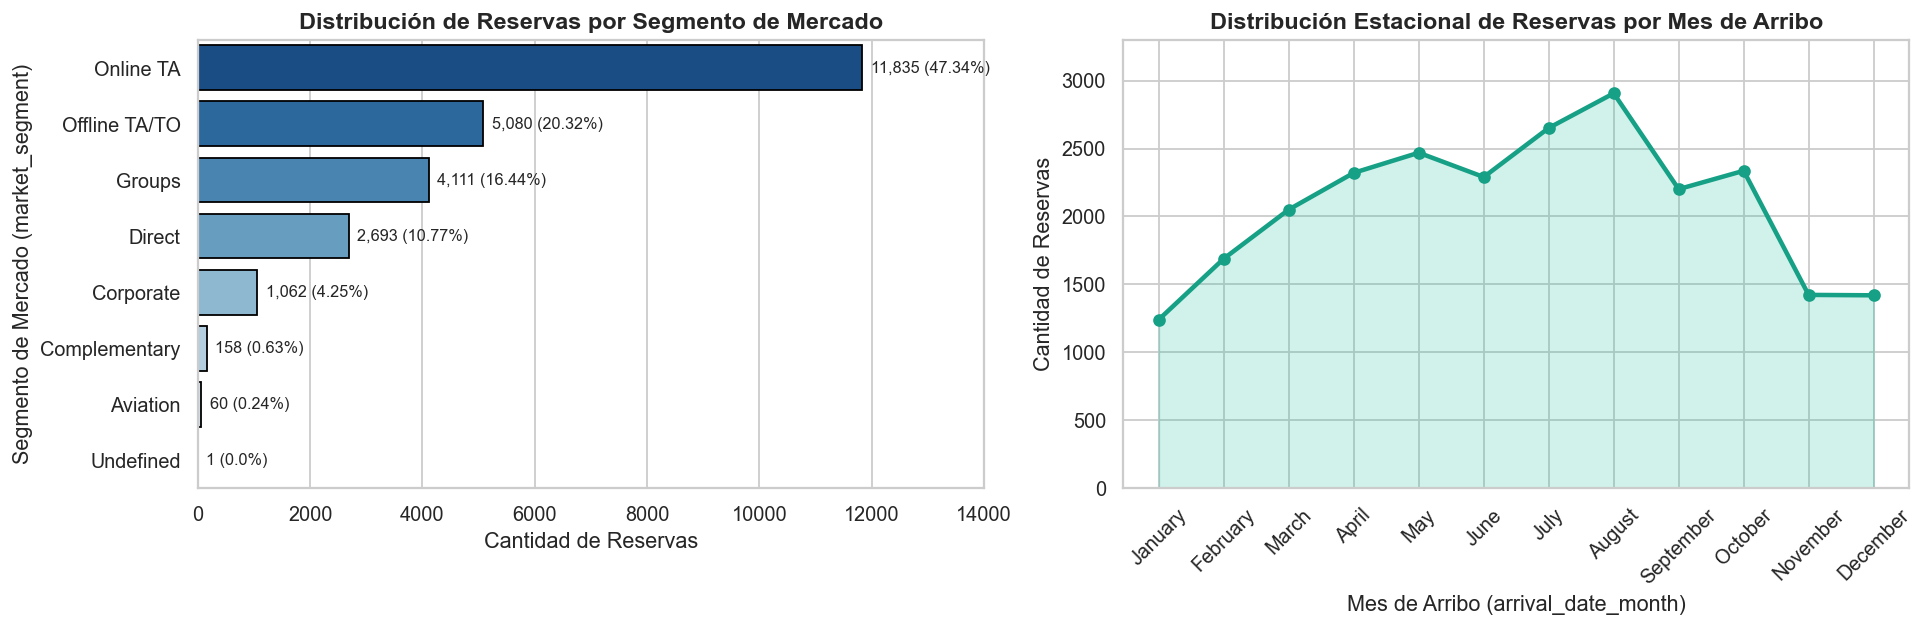

In [12]:
# Visualizaciones iniciales de las variables categóricas y temporales (Semana 9)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: Distribución por Segmento de Mercado
sns.barplot(
    data=freq_segment,
    x="cantidad",
    y="market_segment",
    hue="market_segment",
    palette="Blues_r",
    legend=False,
    ax=axes[0],
    edgecolor="black"
)
axes[0].set_title("Distribución de Reservas por Segmento de Mercado")
axes[0].set_xlabel("Cantidad de Reservas")
axes[0].set_ylabel("Segmento de Mercado (market_segment)")
for i, (cant, pct) in enumerate(zip(freq_segment["cantidad"], freq_segment["porcentaje"])):
    axes[0].text(cant + 150, i, f"{cant:,} ({pct}%)", va="center", fontsize=9)
axes[0].set_xlim(0, 14000)

# Gráfico 2: Distribución por Mes de Arribo
axes[1].plot(freq_month["mes_arribo"], freq_month["cantidad"], marker="o", color="#16a085", linewidth=2.5)
axes[1].fill_between(range(len(freq_month)), freq_month["cantidad"], color="#1abc9c", alpha=0.2)
axes[1].set_title("Distribución Estacional de Reservas por Mes de Arribo")
axes[1].set_xlabel("Mes de Arribo (arrival_date_month)")
axes[1].set_ylabel("Cantidad de Reservas")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(0, 3300)

plt.tight_layout()
plt.show()

**Interpretaciones descriptivas breves de las variables categóricas y temporales (Semana 9):**
* **`hotel`:** Exactamente dos tercios de las observaciones (**16.610 reservas; 66,44%**) corresponden al **`City Hotel`**, mientras que el tercio restante (**8.390 reservas; 33,56%**) pertenece al **`Resort Hotel`**.
* **`market_segment`:** Casi la mitad de las reservas ingresan a través de agencias de viaje en línea (**`Online TA`: 11.835 casos; 47,34%**), seguidas por agencias/operadores tradicionales (**`Offline TA/TO`: 5.080 casos; 20,32%**), contingentes grupales (**`Groups`: 4.111 casos; 16,44%**) y reservas directas (**`Direct`: 2.693 casos; 10,77%**). Los segmentos `Corporate` (4,25%), `Complementary` (0,63%), `Aviation` (0,24%) y `Undefined` (1 solo caso) tienen una participación minoritaria.
* **`arrival_date_month`:** Se aprecia una marcada estacionalidad en el volumen de arribos, alcanzando su pico durante el verano boreal: **agosto (2.906 reservas; 11,62%)** y **julio (2.651 reservas; 10,60%)**, frente a los mínimos registrados en **enero (1.242 reservas; 4,97%)**, **diciembre (5,68%)** y **noviembre (5,69%)**.

---

## 6. Formulación de Preguntas e Hipótesis Exploratorias (Cierre de la Semana 9)

A partir del reconocimiento inicial de las distribuciones individuales, dejamos planteadas las siguientes **cuatro preguntas/hipótesis exploratorias** para profundizar mediante comparaciones entre grupos en la **Semana 10**:

1. **Hipótesis sobre la anticipación (`lead_time`):** *¿Las reservas que se realizan con mayor cantidad de días de anticipación presentan una propensión más alta a cancelarse en comparación con aquellas efectuadas próximas a la fecha de ingreso?*
2. **Hipótesis sobre el perfil comercial (`hotel` y `market_segment`):** *¿Existen diferencias significativas en la tasa de cancelación entre el `City Hotel` y el `Resort Hotel`, y entre los distintos segmentos de mercado (`Online TA`, `Groups`, `Direct`, `Corporate`)?*
3. **Hipótesis sobre estadía, precio y compromiso del cliente (`total_stays_nights`, `adr`, `deposit_type` y `total_of_special_requests`):** *¿Presentan las reservas canceladas y no canceladas comportamientos distintos en la duración de la estadía o en la tarifa diaria promedio, y cómo varían las cancelaciones según el tipo de depósito, el historial de cancelaciones previas o la cantidad de pedidos especiales?*
4. **Hipótesis sobre estacionalidad (`arrival_date_month`):** *¿Varía la proporción de cancelaciones según el mes o la temporada del año en que se concentra la mayor demanda?*

---
# 📗 SEGUNDA PARTE · Entrega 4 (Semana 10): Comparación de Grupos, Patrones y Selección de Variables

## 1. Revisión del Avance de la Semana 9 y Selección de Tres Preguntas Exploratorias

Tras verificar en la Primera Parte que:
* La **unidad de análisis** es cada reserva individual (`25.000` registros únicos sin duplicados),
* La **variable objetivo** `is_canceled` presenta un balance de **62,96% de reservas efectivizadas** (`15.739`) y **37,04% de canceladas** (`9.261`),
* Variables como `lead_time` y `adr` exhiben fuerte asimetría positiva (por lo cual es indispensable acompañar la **media** y el **desvío estándar** con la **mediana** y el **rango intercuartílico**), y
* Los segmentos comerciales tienen tamaños de grupo muy dispares (desde `11.835` en `Online TA` hasta `1` en `Undefined`),

seleccionamos y reformulamos con precisión **tres preguntas/hipótesis exploratorias** para contrastar mediante **SQL + Python**:

> ### 🎯Las Tres Preguntas / Hipótesis Seleccionadas:
> * **Pregunta Exploratoria 1 (Anticipación de la reserva):** *¿En qué medida difiere la distribución de los días de anticipación (`lead_time`) entre las reservas canceladas y las no canceladas, y cómo evoluciona la tasa de cancelación a través de los distintos tramos de anticipación?*
> * **Pregunta Exploratoria 2 (Tipo de hotel y Segmento de mercado):** *¿Qué diferencias existen en la proporción de cancelaciones según el tipo de hotel (`hotel`) y el segmento de mercado (`market_segment`), tanto de manera individual como al cruzar ambas dimensiones comerciales?*
> * **Pregunta Exploratoria 3 (Duración de estadía, Tarifa diaria y Condiciones de compromiso del huésped):** *¿Presentan la duración de la estadía (`total_stays_nights`) y la tarifa diaria (`adr`) diferencias relevantes entre reservas canceladas y efectivizadas, y cómo se asocian el tipo de depósito (`deposit_type`), las cancelaciones previas (`previous_cancellations`) y los pedidos especiales (`total_of_special_requests`) con el comportamiento de cancelación?*

---

## 2. Desarrollo de la Pregunta Exploratoria 1: Anticipación de la Reserva (`lead_time`) vs. Cancelación

### 2.1. Comparación mediante SQL y Resúmenes Descriptivos
Construimos dos consultas SQL complementarias:
1. Una comparación directa de medidas de resumen (cantidad de casos `n`, media, desvío estándar, cuartiles Q1, mediana Q2, Q3, rango intercuartílico RIC y máximo) de `lead_time` agrupando por `is_canceled`.
2. Una segmentación de `lead_time` en **5 tramos de anticipación** para observar cómo varía la proporción de cancelaciones desde reservas de último momento (`0 a 7 días`) hasta reservas de muy largo plazo (`> 180 días`).

In [13]:
# Consulta SQL 1A: Comparación estadística de lead_time entre reservas No Canceladas (0) y Canceladas (1)
comp_lead_time = con.sql("""
SELECT
    is_canceled,
    CASE WHEN is_canceled = 0 THEN 'No Cancelada (0)' ELSE 'Cancelada (1)' END AS estado_reserva,
    COUNT(*) AS n_casos,
    ROUND(AVG(lead_time), 2) AS media_dias,
    ROUND(STDDEV(lead_time), 2) AS desvio_estandar,
    MIN(lead_time) AS min_dias,
    QUANTILE_CONT(lead_time, 0.25) AS q25_dias,
    MEDIAN(lead_time) AS mediana_dias,
    QUANTILE_CONT(lead_time, 0.75) AS q75_dias,
    QUANTILE_CONT(lead_time, 0.75) - QUANTILE_CONT(lead_time, 0.25) AS ric_dias,
    MAX(lead_time) AS max_dias
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
""").df()

comp_lead_time

,is_canceled,estado_reserva,n_casos,media_dias,desvio_estandar,min_dias,q25_dias,mediana_dias,q75_dias,ric_dias,max_dias
0,0,No Cancelada (0),15739,80.28,91.85,0,8.0,45.0,124.0,116.0,542
1,1,Cancelada (1),9261,144.89,118.86,0,49.0,112.0,213.0,164.0,629


In [14]:
# Consulta SQL 1B: Tasa de cancelación según tramos de anticipación (lead_time)
tramos_lead_time = con.sql("""
SELECT
    CASE
        WHEN lead_time <= 7 THEN '1. Corta (0 a 7 días)'
        WHEN lead_time <= 30 THEN '2. Media-Corta (8 a 30 días)'
        WHEN lead_time <= 90 THEN '3. Media (31 a 90 días)'
        WHEN lead_time <= 180 THEN '4. Larga (91 a 180 días)'
        ELSE '5. Muy Larga (> 180 días)'
    END AS tramo_anticipacion,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS reservas_canceladas,
    COUNT(*) - SUM(is_canceled) AS reservas_efectivizadas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(adr), 2) AS adr_promedio
FROM reservas
GROUP BY tramo_anticipacion
ORDER BY tramo_anticipacion
""").df()

tramos_lead_time

,tramo_anticipacion,total_reservas,reservas_canceladas,reservas_efectivizadas,tasa_cancelacion_pct,adr_promedio
0,1. Corta (0 a 7 días),4180,397.0,3783.0,9.50,89.39
1,2. Media-Corta (8 a 30 días),3891,1073.0,2818.0,27.58,107.78
2,3. Media (31 a 90 días),6272,2374.0,3898.0,37.85,108.05
3,4. Larga (91 a 180 días),5485,2522.0,2963.0,45.98,109.77
4,5. Muy Larga (> 180 días),5172,2895.0,2277.0,55.97,92.59


### 2.2. Visualizaciones Exploratorias (Pregunta 1)
Representamos en **Python** tanto la comparación de distribuciones completas mediante un diagrama de caja (*boxplot*) como la progresión escalonada de la tasa de cancelación por tramo de anticipación.

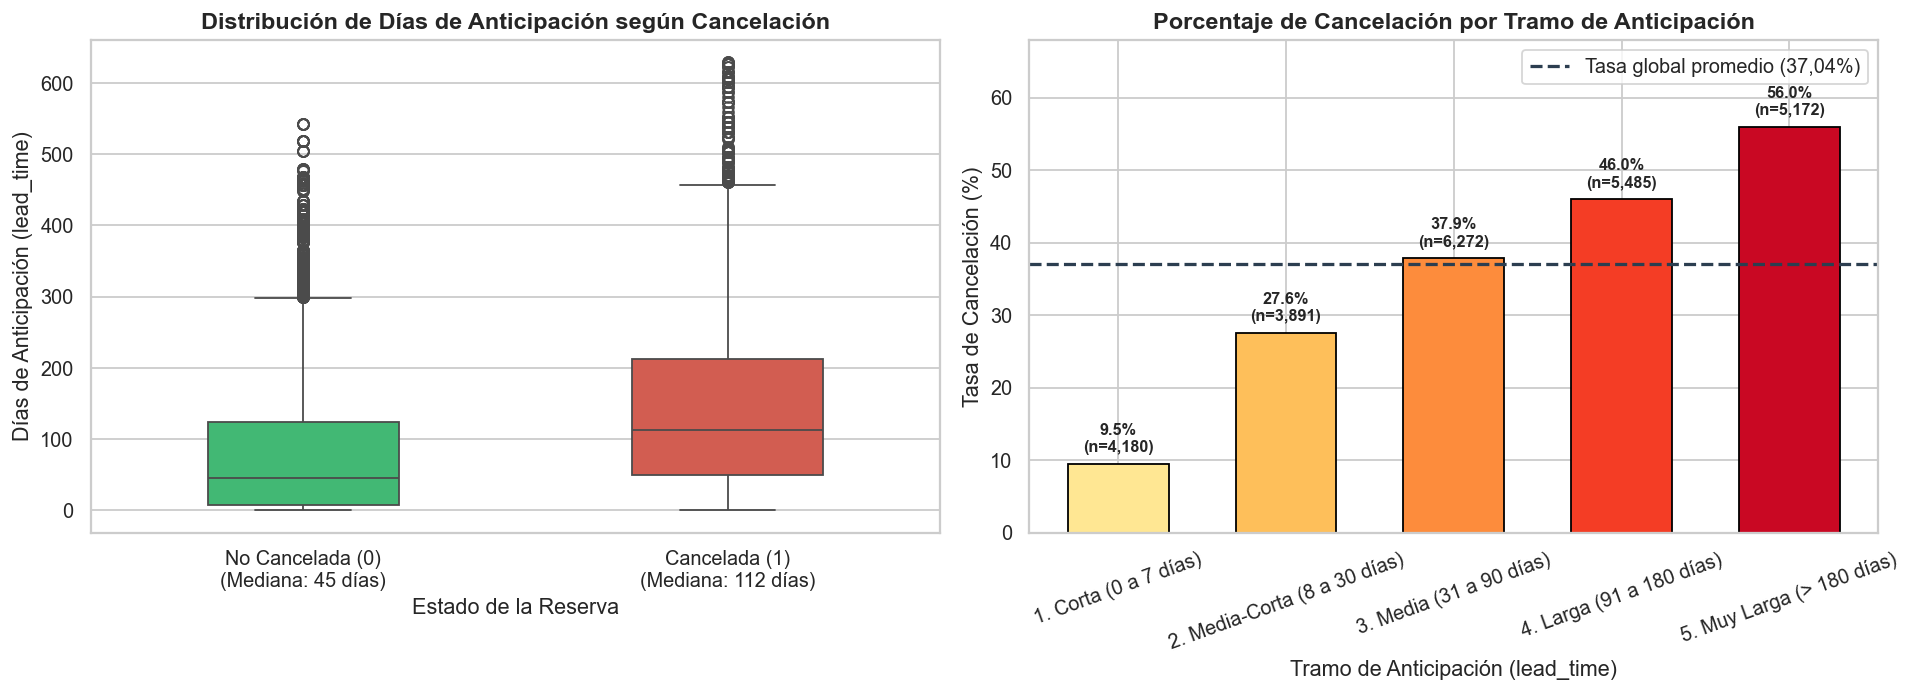

In [15]:
# Visualización Comparativa 1: Boxplot de lead_time por estado + Evolución por tramos de anticipación
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel izquierdo: Boxplot comparativo
sns.boxplot(
    data=df,
    x="is_canceled",
    y="lead_time",
    hue="is_canceled",
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    width=0.45,
    ax=axes[0]
)
axes[0].set_title("Distribución de Días de Anticipación según Cancelación")
axes[0].set_xlabel("Estado de la Reserva")
axes[0].set_ylabel("Días de Anticipación (lead_time)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Cancelada (0)\n(Mediana: 45 días)", "Cancelada (1)\n(Mediana: 112 días)"])

# Panel derecho: Tasa de cancelación por tramo de anticipación
barras_tramo = axes[1].bar(
    tramos_lead_time["tramo_anticipacion"],
    tramos_lead_time["tasa_cancelacion_pct"],
    color=sns.color_palette("YlOrRd", len(tramos_lead_time)),
    edgecolor="black",
    width=0.6
)
axes[1].axhline(37.04, color="#2c3e50", linestyle="--", linewidth=1.8, label="Tasa global promedio (37,04%)")
axes[1].set_title("Porcentaje de Cancelación por Tramo de Anticipación")
axes[1].set_xlabel("Tramo de Anticipación (lead_time)")
axes[1].set_ylabel("Tasa de Cancelación (%)")
axes[1].set_ylim(0, 68)
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend()

for barra, n_tot in zip(barras_tramo, tramos_lead_time["total_reservas"]):
    h = barra.get_height()
    axes[1].annotate(
        f"{h:.1f}%\n(n={n_tot:,})",
        xy=(barra.get_x() + barra.get_width() / 2, h),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### 2.3. Interpretación de la Pregunta Exploratoria 1

* **📊 Resultado observado (lo que muestran las consultas y los gráficos):**
  1. Las reservas **no canceladas (`n = 15.739`)** tienen una anticipación promedio de **80,28 días** ($DE = 91,85$) y una **mediana de 45 días** ($Q_1 = 8$, $Q_3 = 124$, $RIC = 116$ días). En cambio, las reservas **canceladas (`n = 9.261`)** alcanzan una media de **144,89 días** ($DE = 118,86$) y una **mediana de 112 días** ($Q_1 = 49$, $Q_3 = 213$, $RIC = 164$ días), es decir, su mediana es **más del doble (+67 días)** que la del grupo efectivizado.
  2. Al agrupar por tramos en SQL, la tasa de cancelación crece de manera estrictamente monótona en todos los intervalos (todos con más de 3.800 observaciones): pasa de apenas **9,50%** en reservas de corta anticipación (`0 a 7 días`), a **27,58%** (`8 a 30 días`), **37,85%** (`31 a 90 días`), **45,98%** (`91 a 180 días`) y llega al **55,97%** cuando la anticipación supera los **180 días**.
* **💡 Interpretación analítica (con prudencia metodológica):**
  * Existe una asociación positiva muy marcada entre el horizonte temporal de reserva y la ocurrencia de cancelación. Desde la lógica del negocio hotelero, cuanto mayor es el tiempo entre la compra y el viaje, mayor es la exposición del huésped a cambios de planes, imprevistos laborales o hallazgo de ofertas alternativas.
  * **Límite de interpretación:** Esta fuerte asociación **no implica causalidad pura aislada**, ya que las reservas realizadas con más de 180 días suelen estar vinculadas también a contingentes grupales (`Groups`) o bloqueos de operadores turísticos, cuya modalidad de contratación influye simultáneamente en el resultado.

---

## 3. Desarrollo de la Pregunta Exploratoria 2: Tipo de Hotel (`hotel`) y Segmento de Mercado (`market_segment`)

### 3.1. Comparación mediante SQL y Resúmenes Descriptivos
Realizamos tres consultas SQL para evaluar cómo se distribuyen las cancelaciones según la estructura comercial:
1. Comparación por tipo de establecimiento (`City Hotel` vs. `Resort Hotel`).
2. Comparación por segmento de mercado (`market_segment`), incorporando el tamaño de cada grupo (`n`), la tasa de cancelación, la anticipación promedio y la tarifa media.
3. Comparación bivariada cruzada (`hotel` $\times$ `market_segment`) para los segmentos representativos ($n \ge 50$).

In [16]:
# Consulta SQL 2A: Comparación entre City Hotel y Resort Hotel
comp_hotel = con.sql("""
SELECT
    hotel,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    COUNT(*) - SUM(is_canceled) AS no_canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 2) AS lead_time_medio,
    MEDIAN(lead_time) AS lead_time_mediana,
    ROUND(AVG(adr), 2) AS adr_medio,
    ROUND(AVG(total_stays_nights), 2) AS noches_promedio
FROM reservas
GROUP BY hotel
ORDER BY tasa_cancelacion_pct DESC
""").df()

comp_hotel

,hotel,total_reservas,canceladas,no_canceladas,tasa_cancelacion_pct,lead_time_medio,lead_time_mediana,adr_medio,noches_promedio
0,City Hotel,16610,6930.0,9680.0,41.72,110.20,73.0,105.94,2.98
1,Resort Hotel,8390,2331.0,6059.0,27.78,92.37,57.5,94.40,4.32


In [17]:
# Consulta SQL 2B: Comparación por Segmento de Mercado (market_segment)
comp_segment = con.sql("""
SELECT
    market_segment,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    COUNT(*) - SUM(is_canceled) AS no_canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 1) AS lead_time_medio,
    MEDIAN(lead_time) AS lead_time_mediana,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY market_segment
ORDER BY total_reservas DESC
""").df()

comp_segment

,market_segment,total_reservas,canceladas,no_canceladas,tasa_cancelacion_pct,lead_time_medio,lead_time_mediana,adr_medio
0,Online TA,11835,4321.0,7514.0,36.51,83.3,58.0,117.55
1,Offline TA/TO,5080,1781.0,3299.0,35.06,135.9,111.0,88.45
2,Groups,4111,2504.0,1607.0,60.91,187.0,157.0,78.87
3,Direct,2693,415.0,2278.0,15.41,50.6,16.0,114.59
4,Corporate,1062,202.0,860.0,19.02,20.5,7.0,67.72
5,Complementary,158,21.0,137.0,13.29,14.8,3.0,1.72
6,Aviation,60,16.0,44.0,26.67,4.2,3.0,102.26
7,Undefined,1,1.0,0.0,100.00,2.0,2.0,12.00


In [18]:
# Consulta SQL 2C: Cruce simultáneo Tipo de Hotel x Segmento de Mercado (para grupos con n >= 50)
cruce_hotel_segment = con.sql("""
SELECT
    hotel,
    market_segment,
    COUNT(*) AS n_reservas,
    SUM(is_canceled) AS canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 1) AS lead_time_medio,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY hotel, market_segment
HAVING COUNT(*) >= 50
ORDER BY hotel, tasa_cancelacion_pct DESC
""").df()

cruce_hotel_segment

,hotel,market_segment,n_reservas,canceladas,tasa_cancelacion_pct,lead_time_medio,adr_medio
0,City Hotel,Groups,2916,1984.0,68.04,194.5,84.57
1,City Hotel,Offline TA/TO,3505,1549.0,44.19,143.6,94.94
2,City Hotel,Online TA,8128,3013.0,37.07,83.2,119.23
3,City Hotel,Aviation,60,16.0,26.67,4.2,102.26
4,City Hotel,Corporate,571,124.0,21.72,25.4,82.40
5,City Hotel,Direct,1309,230.0,17.57,51.3,120.60
6,City Hotel,Complementary,120,13.0,10.83,11.4,1.18
7,Resort Hotel,Groups,1195,520.0,43.51,168.6,64.98
8,Resort Hotel,Online TA,3707,1308.0,35.28,83.5,113.85
9,Resort Hotel,Corporate,491,78.0,15.89,14.8,50.65


### 3.2. Visualizaciones Exploratorias (Pregunta 2)
Construimos un panel doble en **Python** que muestra: (a) la tasa de cancelación y tamaño de muestra por segmento de mercado, y (b) la comparación cruzada de tasas de cancelación entre `City Hotel` y `Resort Hotel` dentro de cada segmento comercial.

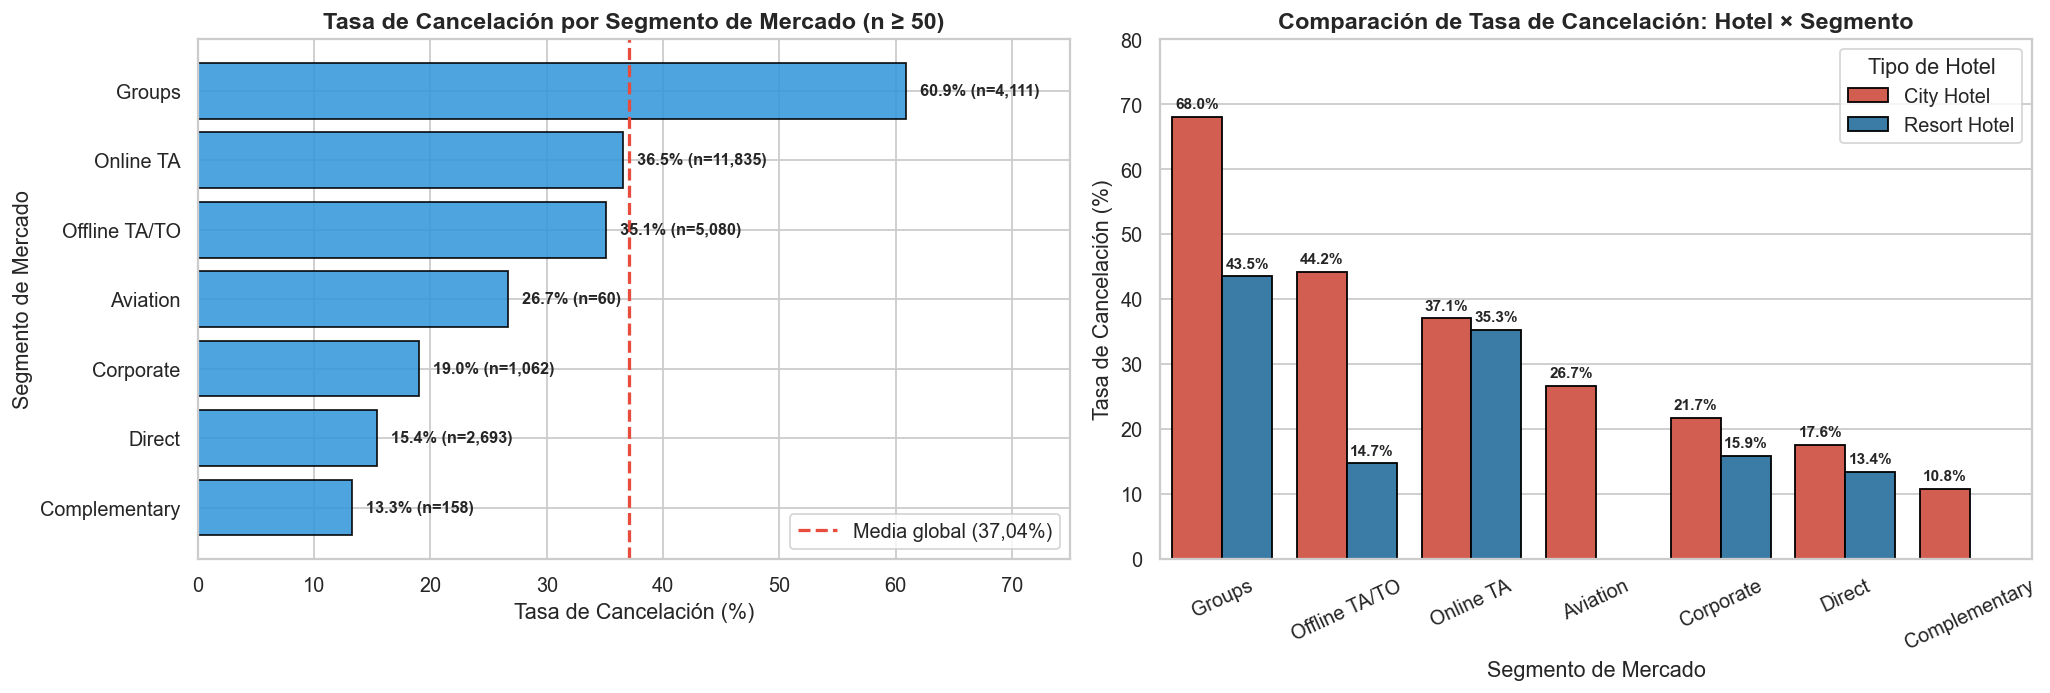

In [19]:
# Visualización Comparativa 2: Tasa de cancelación por Segmento y Cruce con Tipo de Hotel
seg_principales = comp_segment[comp_segment["total_reservas"] >= 50].sort_values("tasa_cancelacion_pct", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Barras horizontales de tasa de cancelación por market_segment
barras_seg = axes[0].barh(
    seg_principales["market_segment"],
    seg_principales["tasa_cancelacion_pct"],
    color="#3498db",
    edgecolor="black",
    alpha=0.88
)
axes[0].axvline(37.04, color="#e74c3c", linestyle="--", linewidth=1.8, label="Media global (37,04%)")
axes[0].set_title("Tasa de Cancelación por Segmento de Mercado (n ≥ 50)")
axes[0].set_xlabel("Tasa de Cancelación (%)")
axes[0].set_ylabel("Segmento de Mercado")
axes[0].set_xlim(0, 75)
axes[0].legend(loc="lower right")

for barra, n_val in zip(barras_seg, seg_principales["total_reservas"]):
    w = barra.get_width()
    axes[0].text(w + 1.2, barra.get_y() + barra.get_height()/2, f"{w:.1f}% (n={n_val:,})", va="center", fontsize=9, fontweight="bold")

# Panel 2: Gráfico de barras agrupadas Hotel x Segmento de Mercado
sns.barplot(
    data=cruce_hotel_segment,
    x="market_segment",
    y="tasa_cancelacion_pct",
    hue="hotel",
    palette=["#e74c3c", "#2980b9"],
    edgecolor="black",
    ax=axes[1]
)
axes[1].set_title("Comparación de Tasa de Cancelación: Hotel × Segmento")
axes[1].set_xlabel("Segmento de Mercado")
axes[1].set_ylabel("Tasa de Cancelación (%)")
axes[1].set_ylim(0, 80)
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(title="Tipo de Hotel")

for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(
            f"{h:.1f}%",
            (p.get_x() + p.get_width() / 2., h),
            ha="center", va="bottom", fontsize=8.5, fontweight="bold", xytext=(0, 3), textcoords="offset points"
        )

plt.tight_layout()
plt.show()

### 3.3. Interpretación de la Pregunta Exploratoria 2

* **📊 Resultado observado (lo que muestran las consultas y los gráficos):**
  1. **Por tipo de hotel:** El **`City Hotel`** presenta una tasa de cancelación del **41,72%** (`6.930` canceladas sobre `16.610` reservas), superando en **13,94 puntos porcentuales** al **`Resort Hotel`**, cuya tasa es del **27,78%** (`2.331` canceladas sobre `8.390` reservas). Además, el `Resort Hotel` exhibe estadías más largas en promedio (`4,31` noches vs. `2,98` noches en el `City Hotel`).
  2. **Por segmento de mercado:** El segmento **`Groups`** lidera ampliamente las cancelaciones con un **60,91%** (`2.504` de `4.111` reservas), seguido por **`Online TA`** (**36,51%**, `n = 11.835`) y **`Offline TA/TO`** (**35,06%**, `n = 5.080`). En el extremo opuesto, las reservas directas (**`Direct`**: **15,41%**, `n = 2.693`), corporativas (**`Corporate`**: **19,02%**, `n = 1.062`) y de cortesía (**`Complementary`**: **13,29%**, `n = 158`) registran las tasas más bajas. (El segmento `Undefined` posee $n = 1$ sola observación, por lo que carece de representatividad estadística).
  3. **Interacción `hotel` $\times$ `market_segment`:** Dentro de *todos* los segmentos principales, el `City Hotel` sufre mayor tasa de cancelación que el `Resort Hotel`. Los contrastes más agudos se dan en **`Groups`** (**68,04%** en `City Hotel` vs. **43,51%** en `Resort Hotel`) y en **`Offline TA/TO`** (**44,19%** en `City Hotel` vs. apenas **14,73%** en `Resort Hotel`).
* **💡 Interpretación analítica (con prudencia metodológica):**
  * El canal comercial y el tipo de establecimiento segmentan claramente el riesgo de cancelación. Las reservas directas (`Direct`) y corporativas (`Corporate`) reflejan clientes con planes definidos y menor intermediación, mientras que las agencias online (`Online TA`) suelen ofrecer facilidades de cancelación gratuita con un clic y los contingentes (`Groups`) suelen bloquear cupos preventivos con alta anticipación (`lead_time` medio de 187 días).
  * Nuevamente, se observa cómo las variables interactúan entre sí: el elevado porcentaje de cancelación en `Groups` coincide con su altísimo `lead_time` promedio (`194,5` días en `City Hotel`), lo que refuerza la necesidad de considerar ambas variables conjuntamente en etapas futuras de modelado.

---

## 4. Desarrollo de la Pregunta Exploratoria 3: Estadía (`total_stays_nights`), Tarifa (`adr`) y Compromiso del Huésped (`deposit_type`, `previous_cancellations`, `total_of_special_requests`)

### 4.1. Comparación mediante SQL y Resúmenes Descriptivos
Analizamos mediante tres consultas SQL si las variables de duración/precio y las variables de compromiso contractual y operativo permiten diferenciar a los clientes que cancelan de los que efectivizan su estadía.

In [20]:
# Consulta SQL 3A: Comparación de duración de estadía (total_stays_nights) y tarifa diaria (adr) según is_canceled
comp_estadia_adr = con.sql("""
SELECT
    is_canceled,
    CASE WHEN is_canceled = 0 THEN 'No Cancelada (0)' ELSE 'Cancelada (1)' END AS estado_reserva,
    COUNT(*) AS n_casos,
    ROUND(AVG(total_stays_nights), 2) AS media_noches,
    ROUND(STDDEV(total_stays_nights), 2) AS desvio_noches,
    QUANTILE_CONT(total_stays_nights, 0.25) AS q25_noches,
    MEDIAN(total_stays_nights) AS mediana_noches,
    QUANTILE_CONT(total_stays_nights, 0.75) AS q75_noches,
    ROUND(AVG(adr), 2) AS media_adr,
    ROUND(STDDEV(adr), 2) AS desvio_adr,
    ROUND(QUANTILE_CONT(adr, 0.25), 2) AS q25_adr,
    ROUND(MEDIAN(adr), 2) AS mediana_adr,
    ROUND(QUANTILE_CONT(adr, 0.75), 2) AS q75_adr
FROM reservas
GROUP BY is_canceled
ORDER BY is_canceled
""").df()

comp_estadia_adr

,is_canceled,estado_reserva,n_casos,media_noches,desvio_noches,q25_noches,mediana_noches,q75_noches,media_adr,desvio_adr,q25_adr,mediana_adr,q75_adr
0,0,No Cancelada (0),15739,3.40,2.62,2.0,3.0,4.0,99.97,49.40,67.15,92.42,125.1
1,1,Cancelada (1),9261,3.48,2.50,2.0,3.0,4.0,105.63,71.74,73.90,96.30,127.0


In [21]:
# Consulta SQL 3B: Comportamiento según Tipo de Depósito (deposit_type) e Historial de Cancelaciones Previas
comp_compromiso = con.sql("""
SELECT
    'Tipo de Depósito: ' || deposit_type AS categoria_analisis,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 1) AS lead_time_medio,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY deposit_type

UNION ALL

SELECT
    CASE
        WHEN previous_cancellations = 0 THEN 'Historial: Sin cancelaciones previas (0)'
        ELSE 'Historial: Con cancelaciones previas (>= 1)'
    END AS categoria_analisis,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(lead_time), 1) AS lead_time_medio,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY categoria_analisis
ORDER BY categoria_analisis
""").df()

comp_compromiso

,categoria_analisis,total_reservas,canceladas,tasa_cancelacion_pct,lead_time_medio,adr_medio
0,Historial: Con cancelaciones previas (>= 1),1333,1236.0,92.72,198.9,76.05
1,Historial: Sin cancelaciones previas (0),23667,8025.0,33.91,98.9,103.53
2,Tipo de Depósito: No Deposit,21936,6237.0,28.43,89.4,103.55
3,Tipo de Depósito: Non Refund,3030,3016.0,99.54,210.9,91.59
4,Tipo de Depósito: Refundable,34,8.0,23.53,169.8,82.92


In [22]:
# Consulta SQL 3C: Relación entre Cantidad de Pedidos Especiales (total_of_special_requests) y Cancelación
comp_requests = con.sql("""
SELECT
    CASE
        WHEN total_of_special_requests >= 3 THEN '3 o más pedidos'
        ELSE CAST(total_of_special_requests AS VARCHAR) || ' pedidos'
    END AS pedidos_especiales,
    COUNT(*) AS total_reservas,
    SUM(is_canceled) AS canceladas,
    COUNT(*) - SUM(is_canceled) AS no_canceladas,
    ROUND(AVG(is_canceled) * 100.0, 2) AS tasa_cancelacion_pct,
    ROUND(AVG(adr), 2) AS adr_medio
FROM reservas
GROUP BY pedidos_especiales
ORDER BY pedidos_especiales
""").df()

comp_requests

,pedidos_especiales,total_reservas,canceladas,no_canceladas,tasa_cancelacion_pct,adr_medio
0,0 pedidos,14773,7052.0,7721.0,47.74,95.28
1,1 pedidos,6850,1493.0,5357.0,21.80,108.74
2,2 pedidos,2766,610.0,2156.0,22.05,117.01
3,3 o más pedidos,611,106.0,505.0,17.35,123.89


### 4.2. Visualizaciones Exploratorias (Pregunta 3)
Construimos en **Python** las visualizaciones comparativas para observar la distribución de `adr` según estado de cancelación, el impacto de los pedidos especiales (`total_of_special_requests`) y las marcadas diferencias según el tipo de depósito e historial previo.

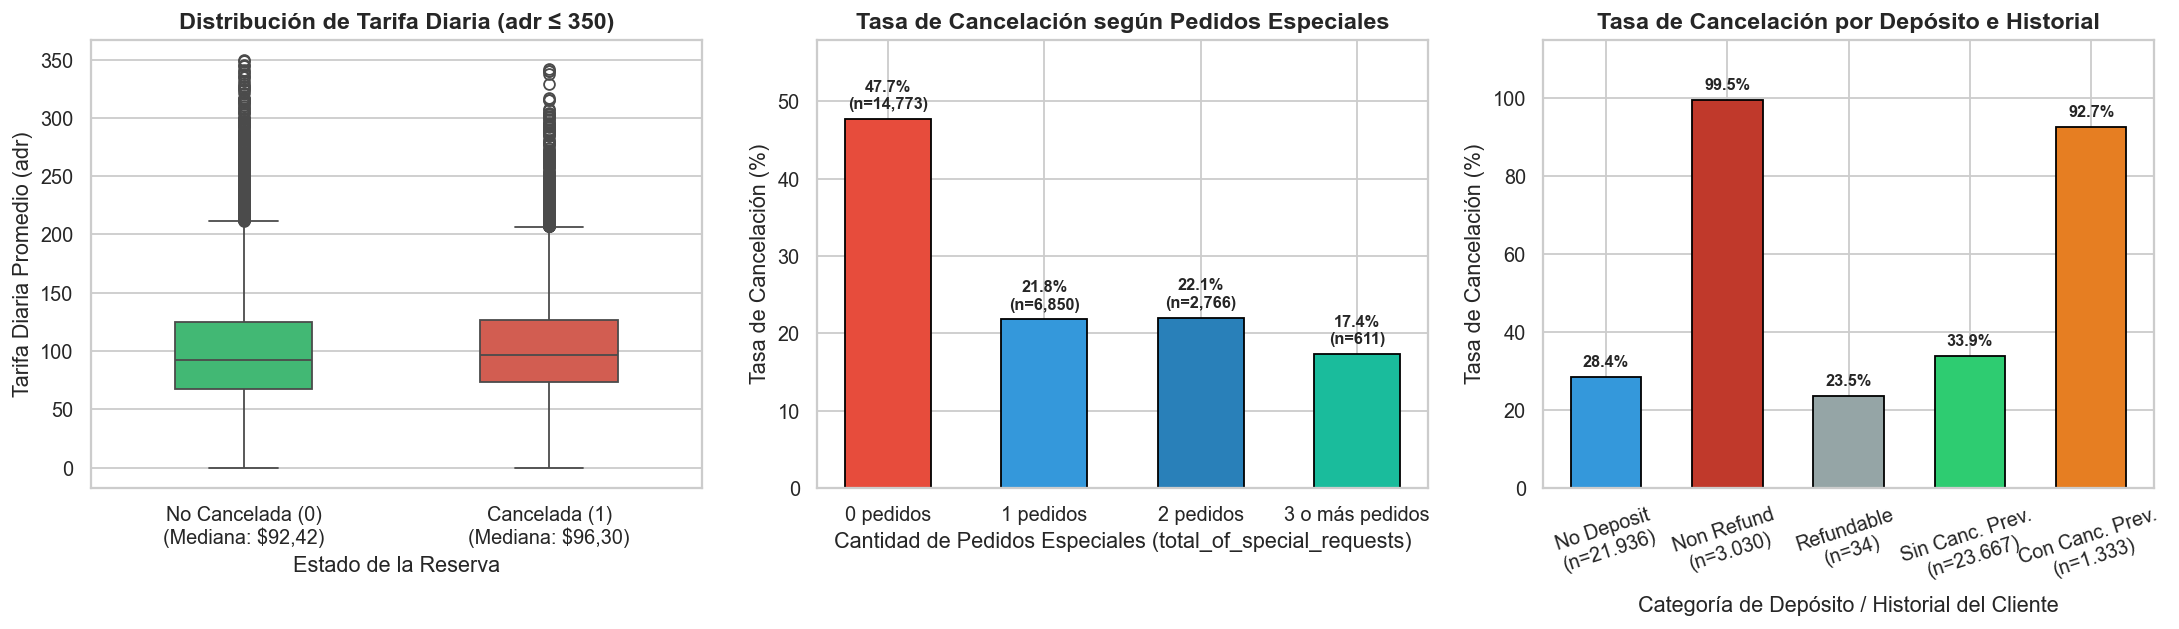

In [23]:
# Visualización Comparativa 3: ADR por cancelación, Pedidos Especiales y Tipo de Depósito / Historial
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1: Boxplot de ADR según is_canceled (acotado a adr <= 350 para visualización limpia de cuartiles)
sns.boxplot(
    data=df[df["adr"] <= 350],
    x="is_canceled",
    y="adr",
    hue="is_canceled",
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    width=0.45,
    ax=axes[0]
)
axes[0].set_title("Distribución de Tarifa Diaria (adr ≤ 350)")
axes[0].set_xlabel("Estado de la Reserva")
axes[0].set_ylabel("Tarifa Diaria Promedio (adr)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Cancelada (0)\n(Mediana: $92,42)", "Cancelada (1)\n(Mediana: $96,30)"])

# Panel 2: Tasa de cancelación según cantidad de pedidos especiales
barras_req = axes[1].bar(
    comp_requests["pedidos_especiales"],
    comp_requests["tasa_cancelacion_pct"],
    color=["#e74c3c", "#3498db", "#2980b9", "#1abc9c"],
    edgecolor="black",
    width=0.55
)
axes[1].set_title("Tasa de Cancelación según Pedidos Especiales")
axes[1].set_xlabel("Cantidad de Pedidos Especiales (total_of_special_requests)")
axes[1].set_ylabel("Tasa de Cancelación (%)")
axes[1].set_ylim(0, 58)
for barra, n_val in zip(barras_req, comp_requests["total_reservas"]):
    h = barra.get_height()
    axes[1].annotate(
        f"{h:.1f}%\n(n={n_val:,})",
        xy=(barra.get_x() + barra.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

# Panel 3: Comparación por Tipo de Depósito e Historial Previo
etiquetas_comp = [
    "No Deposit\n(n=21.936)",
    "Non Refund\n(n=3.030)",
    "Refundable\n(n=34)",
    "Sin Canc. Prev.\n(n=23.667)",
    "Con Canc. Prev.\n(n=1.333)"
]
tasas_comp = [28.43, 99.54, 23.53, 33.91, 92.72]
colores_comp = ["#3498db", "#c0392b", "#95a5a6", "#2ecc71", "#e67e22"]

barras_c = axes[2].bar(etiquetas_comp, tasas_comp, color=colores_comp, edgecolor="black", width=0.58)
axes[2].set_title("Tasa de Cancelación por Depósito e Historial")
axes[2].set_xlabel("Categoría de Depósito / Historial del Cliente")
axes[2].set_ylabel("Tasa de Cancelación (%)")
axes[2].set_ylim(0, 115)
axes[2].tick_params(axis="x", rotation=18)
for barra in barras_c:
    h = barra.get_height()
    axes[2].annotate(
        f"{h:.1f}%",
        xy=(barra.get_x() + barra.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

plt.tight_layout()
plt.show()

### 4.3. Interpretación de la Pregunta Exploratoria 3

* **📊 Resultado observado (lo que muestran las consultas y los gráficos):**
  1. **Duración de la estadía (`total_stays_nights`):** Ambos grupos exhiben exactamente la **misma mediana (3,0 noches)** y el **mismo rango intercuartílico ($Q_1 = 2$, $Q_3 = 4$ noches)**, con medias casi idénticas (`3,40` noches en no canceladas vs. `3,48` noches en canceladas).
  2. **Tarifa diaria promedio (`adr`):** Las reservas canceladas registran una tarifa promedio levemente superior (**\$105,63**, $DE = 71,74$, mediana **\$96,30**) respecto de las no canceladas (**\$99,97**, $DE = 49,40$, mediana **\$92,42**). La mayor dispersión en el grupo cancelado se debe en parte al valor atípico extremo de `adr = 5400`.
  3. **Variables de compromiso e historial:**
     * **Pedidos especiales (`total_of_special_requests`):** Las reservas sin ningún pedido especial (`0 pedidos`, `n = 14.773`) tienen una tasa de cancelación del **47,74%**, mientras que aquellas con al menos `1 pedido especial` (`n = 6.850`) caen abruptamente al **21,80%**, y con `3 o más pedidos` (`n = 611`) descienden al **17,35%**.
     * **Antecedentes (`previous_cancellations`):** Los clientes con al menos una cancelación previa (`n = 1.333`) cancelan el **92,72%** de las veces, frente al **33,91%** de quienes no registran antecedentes (`n = 23.667`).
     * **Tipo de depósito (`deposit_type`):** Mientras que `No Deposit` (`n = 21.936`) tiene un **28,43%** de cancelación, la categoría **`Non Refund` (`n = 3.030`) alcanza un sorprendente 99,54% de cancelación** (`3.016` canceladas).
* **💡 Interpretación analítica (con prudencia metodológica):**
  * La duración total de la estadía por sí sola aporta escasa capacidad discriminante lineal entre ambos grupos, y el precio diario (`adr`) muestra una diferencia moderada (~\$3,88 en la mediana).
  * En cambio, el grado de involucramiento del huésped en la personalización de su estadía (`total_of_special_requests`: pedir cuna, piso alto, vista o cama específica) actúa como un fuerte indicador conductual de compromiso real con el viaje. Asimismo, el historial previo de cancelación (`previous_cancellations`) evidencia una alta persistencia de comportamiento.

---

## 5. Patrones Especiales y Casos Llamativos (Anomalías e Inconsistencias)

Siguiendo el criterio metodológico de **identificar anomalías y segmentos llamativos sin eliminarlos ni corregirlos automáticamente**, ejecutamos consultas SQL específicas para auditar los registros atípicos del dataset.

In [24]:
# Consulta SQL 4A: Cuantificación general de casos llamativos o inusuales en el dataset
anomalias_resumen = con.sql("""
SELECT
    SUM(CASE WHEN adr <= 0 THEN 1 ELSE 0 END) AS casos_adr_cero_o_negativo,
    SUM(CASE WHEN adr > 1000 THEN 1 ELSE 0 END) AS casos_adr_extremo_mayor_1000,
    SUM(CASE WHEN total_stays_nights = 0 THEN 1 ELSE 0 END) AS casos_estadia_0_noches,
    SUM(CASE WHEN total_guests = 0 THEN 1 ELSE 0 END) AS casos_sin_huespedes_0,
    SUM(CASE WHEN lead_time > 365 THEN 1 ELSE 0 END) AS casos_anticipacion_mayor_1_anio,
    SUM(CASE WHEN deposit_type = 'Non Refund' THEN 1 ELSE 0 END) AS casos_non_refund
FROM reservas
""").df()

anomalias_resumen

,casos_adr_cero_o_negativo,casos_adr_extremo_mayor_1000,casos_estadia_0_noches,casos_sin_huespedes_0,casos_anticipacion_mayor_1_anio,casos_non_refund
0,423.0,1.0,141.0,32.0,676.0,3030.0


In [25]:
# Consulta SQL 4B: Inspección puntual de los registros con valores extremos en ADR y estadías largas
casos_extremos = con.sql("""
SELECT
    booking_id, hotel, is_canceled, lead_time, adr,
    total_stays_nights, total_guests, market_segment, deposit_type
FROM reservas
WHERE adr > 450 OR total_stays_nights > 45 OR total_guests > 10
ORDER BY adr DESC, total_stays_nights DESC
LIMIT 10
""").df()

casos_extremos

,booking_id,hotel,is_canceled,lead_time,adr,total_stays_nights,total_guests,market_segment,deposit_type
0,HB-048516,City Hotel,1,35,5400.0,1,2,Offline TA/TO,Non Refund
1,HB-014038,Resort Hotel,0,113,110.5,60,1,Direct,No Deposit
2,HB-014039,Resort Hotel,0,126,110.0,69,1,Direct,No Deposit
3,HB-002419,Resort Hotel,1,334,0.0,7,20,Direct,No Deposit
4,HB-002165,Resort Hotel,1,361,0.0,7,26,Offline TA/TO,No Deposit
5,HB-001885,Resort Hotel,1,347,0.0,7,26,Offline TA/TO,No Deposit


### Análisis de los Patrones y Casos Llamativos Detectados:

1. **Caso extremo de tarifa diaria (`adr = 5.400,00` en `booking_id = 'HB-048516'`):**
   * Existe una única reserva en `City Hotel` (`Offline TA/TO`, `Non Refund`, `is_canceled = 1`) con `adr = 5400.0`, más de 10 veces superior al segundo valor más alto del dataset (`adr = 508.0` en `HB-015084`). Si bien distorsiona la media y el desvío estándar del grupo cancelado, **no se elimina en esta etapa**, dejando documentada la conveniencia de utilizar medianas o aplicar un filtro/winsorización antes del modelado predictivo.
2. **Reservas con tarifa `adr = 0` (`423` casos) y estadías de `0 noches` (`141` casos):**
   * Las 423 observaciones con `adr = 0` pueden corresponder a estadías bonificadas (`Complementary`), canjes de programas de fidelidad o errores de carga administrativa. Por su parte, las 141 reservas con `total_stays_nights = 0` suelen representar usos diurnos de habitación (*day-use*) o reservas dadas de baja el mismo día del *check-in*.
3. **Reservas con `total_guests = 0` (`32` casos con 0 adultos, 0 niños y 0 bebés):**
   * Constituyen una inconsistencia lógica de registro (una habitación reservada sin ocupantes declarados), posiblemente originada en bloqueos administrativos de habitaciones o errores de captura del sistema PMS del hotel.
4. **El patrón contraintuitivo de `deposit_type = 'Non Refund'` (`3.030` casos con 99,54% de cancelación):**
   * Intuitivamente, un depósito "no reembolsable" debería desalentar la cancelación; sin embargo, en este dataset presenta un **99,54% de cancelaciones** y un `lead_time` medio de **210,9 días**. En la literatura sobre este dataset hotelero (Antonio, de Almeida & Nunes, 2019), este fenómeno se explica porque muchas reservas de operadores y grupos con tarifas promocionales no reembolsables se cargan bajo esta etiqueta cuando entran en disputa de pago o cancelación masiva de cupos, o bien constituye una variable con potencial *fuga de información* (*data leakage*) si la marca se actualiza al momento de retener el depósito tras una cancelación.

---

## 6. Selección y Justificación de Variables Candidatas para Modelado Posterior

Con base en la evidencia empírica recolectada durante el Análisis Exploratorio de Datos, seleccionamos y justificamos las **variables candidatas** más relevantes para predecir `is_canceled` en las próximas etapas del TPI:

| Variable Candidata | Naturaleza | Nivel de Relevancia | Justificación Basada en la Evidencia del EDA |
|---|---|---|---|
| **`lead_time`** | Cuantitativa discreta | **Muy Alta** | Muestra una separación neta entre grupos (mediana de 112 días en canceladas vs. 45 días en no canceladas) y un incremento monotónico de la tasa de cancelación del 9,50% al 55,97%. |
| **`market_segment`** | Categórica nominal | **Muy Alta** | Discrimina fuertemente el riesgo según el canal comercial: desde el 15,41% en ventas directas (`Direct`) y 19,02% en `Corporate`, hasta el 36,51% en `Online TA` y 60,91% en `Groups`. |
| **`total_of_special_requests`** | Cuantitativa discreta | **Alta** | Captura el compromiso conductual del cliente: quienes realizan 1 o más pedidos especiales cancelan menos de la mitad (21,80% a 17,35%) que quienes no registran ninguno (47,74%). |
| **`previous_cancellations`** | Cuantitativa / Binaria | **Alta** | El historial previo de cancelación (`> 0`) se asocia con un 92,72% de reincidencia frente a 33,91% en clientes sin antecedentes. |
| **`hotel`** | Categórica binaria | **Alta** | El establecimiento urbano (`City Hotel`: 41,72%) presenta un riesgo basal significativamente mayor que el vacacional (`Resort Hotel`: 27,78%) e interactúa con el segmento comercial. |
| **`deposit_type`** | Categórica nominal | **Alta (con precaución)** | Posee altísima capacidad predictiva estadística (`Non Refund` = 99,54% cancelado vs. `No Deposit` = 28,43%), pero deberá evaluarse en el modelado con y sin esta variable para descartar posible *data leakage*. |
| **`adr`** | Cuantitativa continua | **Media** | Aporta información sobre el nivel tarifario (mediana de \$96,30 en canceladas vs. \$92,42 en no canceladas), especialmente útil en interacción con el mes de arribo y el tipo de hotel, previo tratamiento del outlier de \$5.400. |
| **`arrival_date_month`** y **`total_stays_nights`** | Temporal / Cuantitativa | **Media-Baja (Complementaria)** | Aunque `total_stays_nights` no difiere en mediana de forma aislada (3 noches en ambos grupos), combinada con la estacionalidad mensual (`arrival_date_month`) ayuda a caracterizar el perfil vacacional vs. corporativo. |

---

## 7. Conclusiones Exploratorias (Síntesis de Tres Hallazgos Principales)

1. **Hallazgo 1 — La anticipación (`lead_time`) es el principal factor cuantitativo asociado a la cancelación:**
   * *Qué muestran los datos:* Las reservas canceladas presentan una mediana de anticipación de **112 días** ($RIC = 164$) frente a **45 días** ($RIC = 116$) en las reservas efectivizadas. La proporción de cancelación se multiplica por casi seis veces entre las reservas realizadas dentro de la última semana (**9,50%**) y aquellas efectuadas con más de seis meses de antelación (**55,97%**).
   * *Interpretación:* Los horizontes de reserva extensos incrementan sustancialmente la incertidumbre del viaje y la probabilidad de anulación.

2. **Hallazgo 2 — Existe una brecha estructural según el tipo de hotel y el canal de comercialización (`hotel` y `market_segment`):**
   * *Qué muestran los datos:* El **`City Hotel`** registra un **41,72%** de cancelaciones frente al **27,78%** del **`Resort Hotel`**. Al desglosar por segmento comercial, los contingentes (**`Groups`**: **60,91%** general y **68,04%** en `City Hotel`) y las agencias online (**`Online TA`**: **36,51%**) concentran las mayores tasas de baja, mientras que la venta directa (**`Direct`**: **15,41%**) y corporativa (**`Corporate`**: **19,02%**) muestran alta estabilidad.
   * *Interpretación:* Las reservas intermediadas o asociadas a bloqueos grupales presentan menor fidelidad o mayor flexibilidad de cancelación que aquellas gestionadas directamente por el huésped o por cuenta empresarial.

3. **Hallazgo 3 — Las señales de compromiso e historial del huésped superan en poder discriminante al precio o duración aislados:**
   * *Qué muestran los datos:* Mientras que la duración de la estadía (`total_stays_nights`) comparte idéntica mediana (**3 noches**) en ambos grupos y la tarifa diaria (`adr`) exhibe una diferencia moderada en mediana (**\$96,30** vs. **\$92,42**), el registro de al menos un pedido especial (`total_of_special_requests >= 1`) reduce la tasa de cancelación del **47,74% al 21,80%**, y la presencia de cancelaciones previas (`previous_cancellations > 0`) eleva la tasa al **92,72%**.
   * *Interpretación:* Las acciones concretas de personalización del viaje y la conducta histórica del cliente ofrecen señales tempranas sumamente valiosas sobre la intención real de hospedarse.

---

## 8. Alcances y Limitaciones del Análisis

Antes de tomar decisiones operativas o avanzar hacia el entrenamiento de modelos predictivos, deben reconocerse al menos **tres limitaciones metodológicas fundamentales** de esta etapa exploratoria:

1. **Asociación estadística no equivale a causalidad (Presencia de variables confusoras):**
   * Las diferencias observadas en análisis bivariados pueden estar mediadas por terceras variables (*confounders*). Por ejemplo, la elevada tasa de cancelación del segmento `Groups` (60,91%) no se debe únicamente al canal en sí, sino también a que dicho segmento reserva con una anticipación promedio mucho mayor (`187,0` días) que el segmento `Direct` (`50,6` días). Todavía no se ha estimado el efecto neto de cada variable controlando simultáneamente por las demás.
2. **Posible sesgo operativo en `deposit_type` (*Non Refund*) y presencia de registros anómalos sin depurar:**
   * La tasa de cancelación del **99,54%** en reservas con depósito `Non Refund` requiere cautela antes de incluirla acríticamente en un modelo, ya que podría reflejar una convención contable o administrativa del sistema hotelero posterior al incumplimiento del cliente. Asimismo, existen registros inusuales (`1` caso con `adr = 5400`, `423` casos con `adr = 0` y `32` casos con `total_guests = 0`) que fueron conservados para diagnóstico exploratorio pero requerirán reglas de filtrado o imputación en la etapa de preprocesamiento para modelado.
3. **Variables no observadas en el dataset:**
   * El conjunto de datos no incluye factores externos como condiciones climáticas, eventos locales, precios de hoteles competidores ni la **antigüedad con la que se produjo la cancelación** respecto de la fecha de llegada (no es igual para el hotel una cancelación ocurrida 90 días antes del *check-in* que una ocurrida 24 horas antes).

In [26]:
# Cierre limpio de la conexión a DuckDB al finalizar el notebook
con.close()
print("🔒 Conexión a DuckDB cerrada correctamente. Notebook ejecutado de principio a fin sin errores.")

🔒 Conexión a DuckDB cerrada correctamente. Notebook ejecutado de principio a fin sin errores.


# 🧩 Trabajo Práctico Integrador · Entrega 5: Primer Modelo Predictivo e Interpretación Inicial

* **Institución:** Universidad Tecnológica Nacional (UTN) — Tecnicatura Universitaria en Programación a Distancia
* **Materia:** Introducción al Análisis de Datos (Unidad N° 5 · Introducción al Aprendizaje Automático)
* **Comisión:** 8
* **Integrantes del Equipo:**
  * **López, Emanuel Gustavo** (Legajo: 101135)
  * **Del Corro, Santino**
* **Número de Entrega:** Entrega N° 5 (Notebook independiente y reproducible)
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H — 25.000 reservas)
* **Variable Objetivo:** `is_canceled` (`1` = Reserva Cancelada, `0` = Reserva No Cancelada)
* **Recorrido Elegido:** **SQL (DuckDB) + Python (`pandas`, `scikit-learn`, `matplotlib`, `seaborn`)**

---

## Introducción y Definición del Problema Predictivo

Durante la Semana 11 definimos el problema de las cancelaciones de reservas hoteleras como una tarea de **Aprendizaje Supervisado de Clasificación Binaria**:
* **Variable objetivo ($Y$):** `is_canceled`, variable discreta binaria que toma el valor `1` cuando la reserva se cancela y `0` cuando el huésped realiza el *check-in* y efectiviza su estadía.
* **Propósito:** Construir un primer modelo de árbol de decisión (`DecisionTreeClassifier`) a partir de características conocidas al momento de la reserva ($X$), generar predicciones sobre un conjunto de prueba y realizar una interpretación crítica inicial de sus resultados y limitaciones.

In [1]:
# 0. Preparación automática del entorno y carga reproducible del dataset (Local o GitHub en Colab)
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

for package in ["duckdb", "pandas", "scikit-learn", "matplotlib", "seaborn"]:
    module = "sklearn" if package == "scikit-learn" else package
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")

GITHUB_RAW_URL = "https://raw.githubusercontent.com/Emanstor/tpi-iad-comision8/main/hotel%20booking%20TPI%20grupo%20H.csv"
POSSIBLE_PATHS = [
    Path("hotel booking TPI grupo H.csv"),
    Path("sample_data/hotel booking TPI grupo H.csv"),
    Path("hotel booking TPI grupo H (3).csv")
]

data_path = next((p for p in POSSIBLE_PATHS if p.exists()), None)
if data_path is None:
    data_path = Path("hotel booking TPI grupo H.csv")
    print("Descargando dataset original desde el repositorio GitHub del equipo...")
    urlretrieve(GITHUB_RAW_URL, data_path)

reservas_original = pd.read_csv(data_path)
con = duckdb.connect(":memory:")
con.register("reservas_original", reservas_original)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_original")

print(f"✅ Entorno preparado: {len(reservas_original):,} reservas registradas en la tabla 'reservas' de DuckDB.")

✅ Entorno preparado: 25,000 reservas registradas en la tabla 'reservas' de DuckDB.


---
## Paso 1 · Preparar los datos para el modelo (Selección SQL, Exclusiones por Fuga de Información, Faltantes y Categóricas)

### 1.1. Justificación de exclusiones para evitar Fuga de Información (*Data Leakage*) y ruido
Al construir un modelo predictivo, solo deben incluirse variables cuyo valor se conozca legítimamente antes de que ocurra el evento a predecir. Por ello, excluimos en la consulta SQL:
1. **`assigned_room_type` (Tipo de habitación asignada):** A diferencia de `reserved_room_type`, la habitación finalmente asignada suele confirmarse o modificarse operativamente en la recepción al momento del *check-in* (cuando la reserva ya no se canceló), por lo que incluirla introduciría **fuga de información (*data leakage*)**.
2. **`booking_id`:** Es un código identificador único de cada fila (`HB-024689`); no representa un atributo generalizable del cliente ni del viaje.
3. **`company` y `agent`:** Además de ser códigos identificadores de intermediarios, `company` presenta un **94,32% de valores nulos** (`23.580` faltantes sobre `25.000` filas), información que ya queda mejor representada por las variables `market_segment` y `distribution_channel`.
4. **`arrival_date` (fecha exacta de calendario):** Se excluye la fecha puntual para evitar que el árbol memorice días específicos de un año histórico, conservando el comportamiento temporal general a través de `lead_time` y la duración de la estadía.

### 1.2. Diagnóstico mediante SQL de valores faltantes y selección de variables
Verificamos mediante SQL los valores faltantes en el dataset y extraemos las variables predictoras seleccionadas:
* **Predictoras cuantitativas:** `lead_time`, `stays_in_weekend_nights`, `stays_in_week_nights`, `adults`, `children` (registra **1 valor faltante**, que se imputará en el Paso 2 usando exclusivamente la mediana de entrenamiento), `babies`, `previous_cancellations`, `booking_changes`, `adr`, `required_car_parking_spaces`, `total_of_special_requests`.
* **Predictoras categóricas a codificar:** `hotel`, `market_segment`, `deposit_type` y `customer_type`.

In [2]:
# Diagnóstico mediante SQL de valores faltantes en las columnas del dataset original
con.sql("""
SELECT
    COUNT(*) - COUNT(children) AS nulos_children,
    COUNT(*) - COUNT(country) AS nulos_country,
    COUNT(*) - COUNT(agent) AS nulos_agent,
    COUNT(*) - COUNT(company) AS nulos_company,
    COUNT(*) - COUNT(lead_time) AS nulos_lead_time,
    COUNT(*) - COUNT(adr) AS nulos_adr
FROM reservas
""").df()

,nulos_children,nulos_country,nulos_agent,nulos_company,nulos_lead_time,nulos_adr
0,1,97,3403,23580,0,0


In [3]:
# Consulta SQL para recuperar la variable objetivo (is_canceled) y los predictores seleccionados (sin variables con leakage)
df_modelo = con.sql("""
SELECT
    is_canceled,
    lead_time,
    stays_in_weekend_nights,
    stays_in_week_nights,
    adults,
    children,
    babies,
    previous_cancellations,
    booking_changes,
    adr,
    required_car_parking_spaces,
    total_of_special_requests,
    hotel,
    market_segment,
    deposit_type,
    customer_type
FROM reservas
""").df()

print(f"Datos seleccionados con SQL: {df_modelo.shape[0]:,} filas y {df_modelo.shape[1]} columnas.")
df_modelo.head()

Datos seleccionados con SQL: 25,000 filas y 16 columnas.


,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,booking_changes,adr,required_car_parking_spaces,total_of_special_requests,hotel,market_segment,deposit_type,customer_type
0,1,85,4,10,2,1.0,0,1,0,217.14,0,2,Resort Hotel,Direct,No Deposit,Group
1,1,77,0,2,2,0.0,0,0,1,79.20,0,2,City Hotel,Online TA,No Deposit,Transient
2,0,91,2,4,1,0.0,0,0,1,132.60,0,1,City Hotel,Online TA,No Deposit,Transient
3,0,0,0,1,2,0.0,0,0,0,75.00,0,2,Resort Hotel,Online TA,No Deposit,Transient
4,0,133,2,3,2,0.0,0,0,0,70.04,0,2,City Hotel,Online TA,No Deposit,Transient


---
## Paso 2 · Separar Entrenamiento y Prueba e Imputar Valores Faltantes sin Fuga de Datos

1. Dividimos el dataset de manera reproducible (`random_state=42`) y estratificada (`stratify=y`) en **Entrenamiento (70% = 17.500 reservas)** y **Prueba (30% = 7.500 reservas)**.
2. **Regla metodológica para valores faltantes:** Como la columna `children` posee un valor faltante (`NaN`), calculamos su **mediana únicamente a partir del conjunto de entrenamiento (`X_train["children"].median()`)** y utilizamos ese valor para completar tanto `X_train` como `X_test`. De esta manera evitamos que información del conjunto de prueba contamine el preprocesamiento.
3. A partir de las columnas ya limpias, calculamos las variables derivadas `total_stays_nights` y `total_guests` y transformamos las variables categóricas a formato numérico mediante *One-Hot Encoding* (`pd.get_dummies`), alineando las columnas de `X_test` con las de `X_train`.

In [4]:
# 1. Separar variable objetivo (y) y predictores (X)
y = df_modelo["is_canceled"]
X = df_modelo.drop(columns="is_canceled")

# 2. División reproducible en entrenamiento (70%) y prueba (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Completar valores faltantes en 'children' usando la mediana calculada SOLO en entrenamiento
mediana_children_train = X_train["children"].median()
X_train["children"] = X_train["children"].fillna(mediana_children_train)
X_test["children"] = X_test["children"].fillna(mediana_children_train)

# 4. Construcción de las variables derivadas (total_stays_nights y total_guests)
for subconjunto in [X_train, X_test]:
    subconjunto["total_stays_nights"] = subconjunto["stays_in_weekend_nights"] + subconjunto["stays_in_week_nights"]
    subconjunto["total_guests"] = subconjunto["adults"] + subconjunto["children"] + subconjunto["babies"]

columnas_ordenadas = [
    "lead_time", "total_stays_nights", "total_guests", "previous_cancellations",
    "booking_changes", "adr", "required_car_parking_spaces", "total_of_special_requests",
    "hotel", "market_segment", "deposit_type", "customer_type"
]
X_train = X_train[columnas_ordenadas]
X_test = X_test[columnas_ordenadas]

# 5. Codificación de variables categóricas (One-Hot Encoding) usando las categorías de entrenamiento
columnas_categoricas = ["hotel", "market_segment", "deposit_type", "customer_type"]
X_train = pd.get_dummies(X_train, columns=columnas_categoricas, drop_first=True)
X_test = pd.get_dummies(X_test, columns=columnas_categoricas, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"Mediana de 'children' calculada en X_train: {mediana_children_train}")
print(f"Nulos restantes en X_train: {X_train.isnull().sum().sum()} | Nulos en X_test: {X_test.isnull().sum().sum()}")
print(f"Dimensiones finales -> X_train: {X_train.shape} | X_test: {X_test.shape}")

Mediana de 'children' calculada en X_train: 0.0
Nulos restantes en X_train: 0 | Nulos en X_test: 0
Dimensiones finales -> X_train: (17500, 20) | X_test: (7500, 20)


---
## Paso 3 · Entrenar un Primer Modelo de Clasificación (Árbol de Decisión)

Entrenamos un clasificador `DecisionTreeClassifier(max_depth=3, random_state=42)` utilizando exclusivamente los datos de entrenamiento (`X_train`, `y_train`). La profundidad máxima de 3 niveles permite obtener reglas claras e interpretables.

In [5]:
# Entrenamiento del Árbol de Decisión para clasificación
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

print("✅ Árbol de decisión entrenado correctamente sobre las 17.500 reservas de entrenamiento.")

✅ Árbol de decisión entrenado correctamente sobre las 17.500 reservas de entrenamiento.


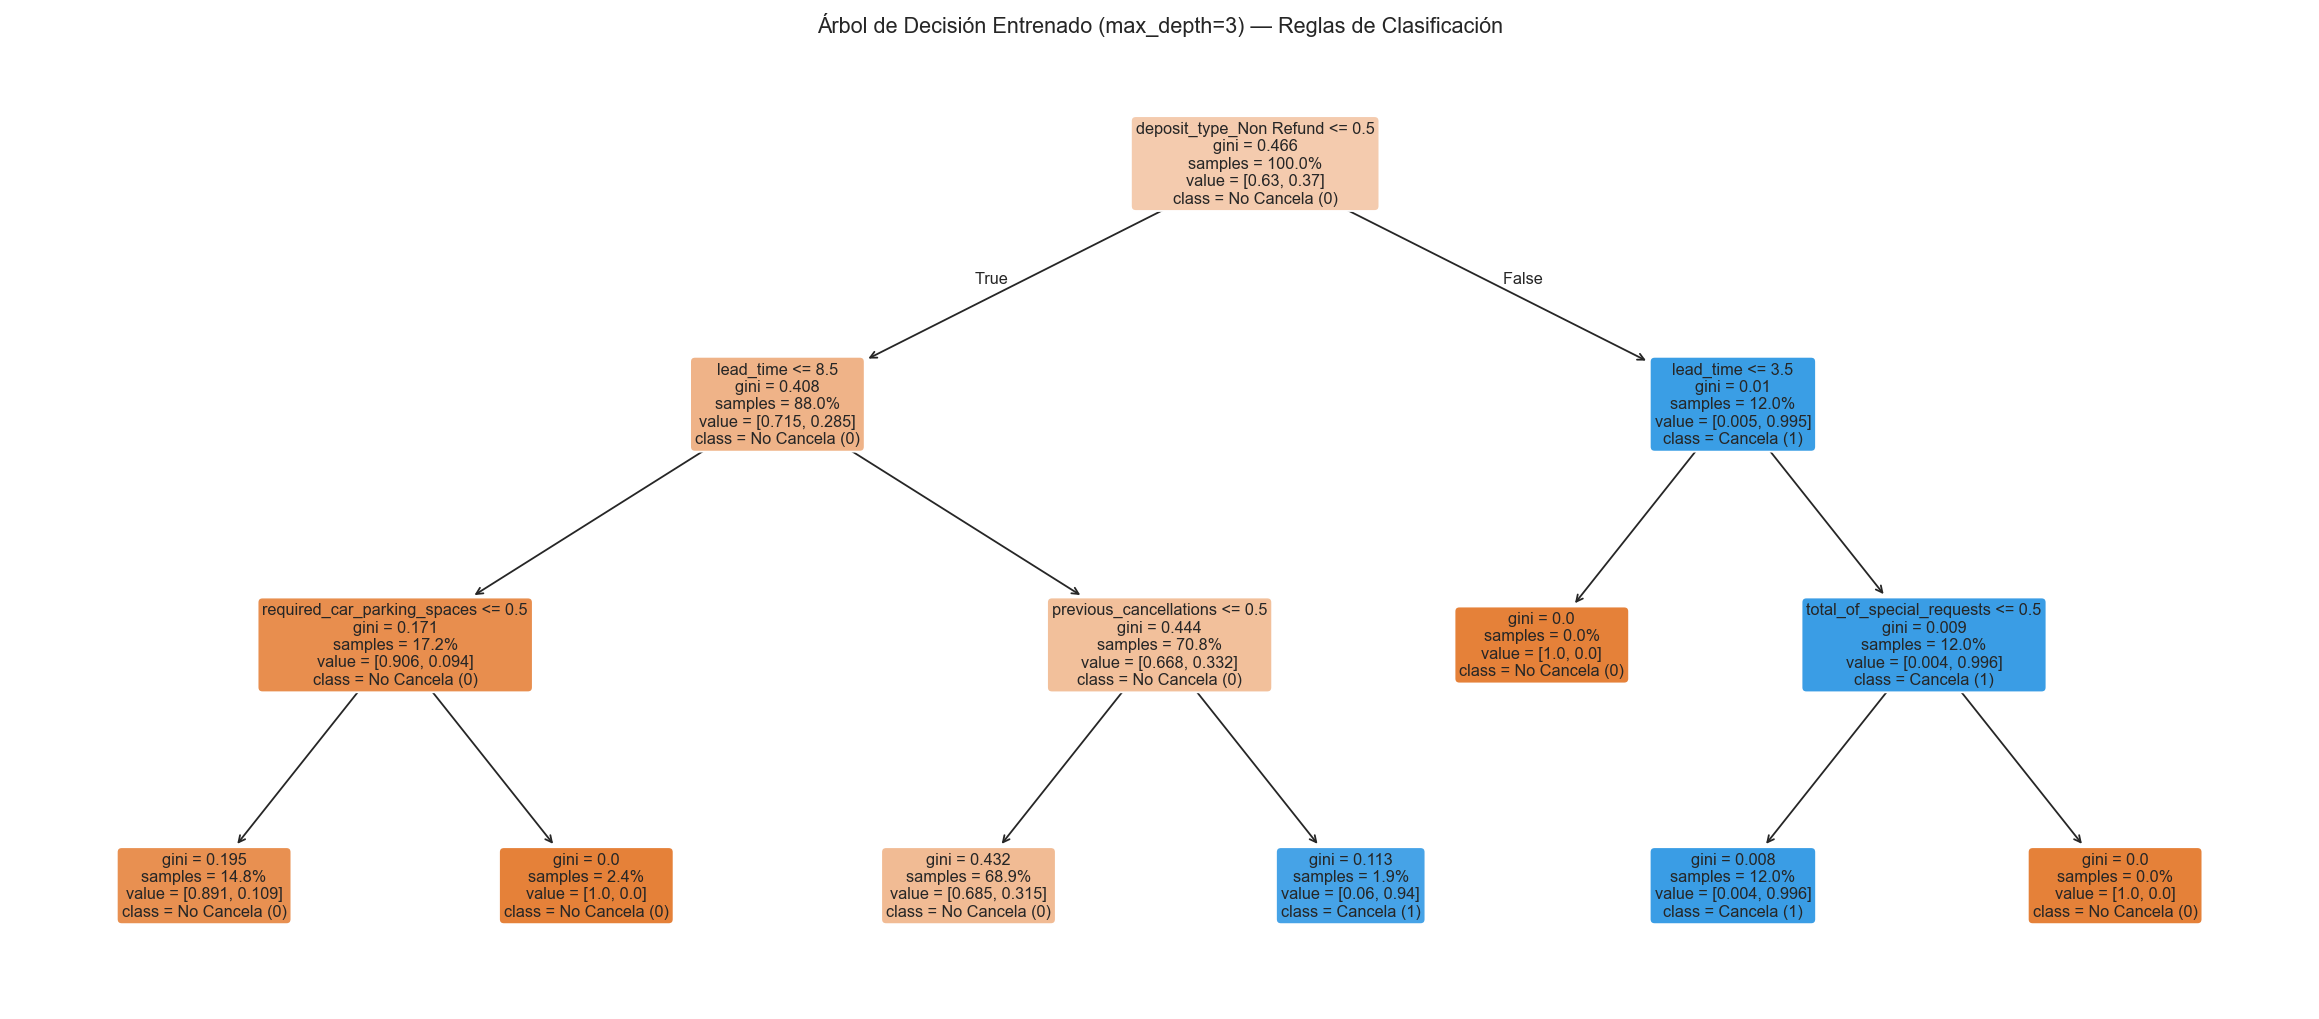

In [6]:
# Visualización de las reglas aprendidas por el Árbol de Decisión
plt.figure(figsize=(18, 8))
plot_tree(
    modelo,
    feature_names=X_train.columns,
    class_names=["No Cancela (0)", "Cancela (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    proportion=True
)
plt.title("Árbol de Decisión Entrenado (max_depth=3) — Reglas de Clasificación")
plt.tight_layout()
plt.show()

---
## Paso 4 · Generar e Inspeccionar Predicciones sobre el Conjunto de Prueba

Aplicamos el modelo entrenado sobre las `7.500` observaciones del conjunto de prueba (`X_test`) para obtener tanto la **categoría predicha (`0` o `1`)** como la **probabilidad estimada de cancelación**, y comparamos mediante **SQL** los valores predichos frente a los valores reales (`y_test`).

In [7]:
# Generación de predicciones y probabilidades sobre el conjunto de prueba (X_test)
predicciones = modelo.predict(X_test)
probabilidades = modelo.predict_proba(X_test)[:, 1]

# Armado de tabla comparativa y registro en DuckDB para inspección mediante SQL
comparacion_test = pd.DataFrame({
    "lead_time": X_test["lead_time"].to_numpy(),
    "previous_cancellations": X_test["previous_cancellations"].to_numpy(),
    "total_of_special_requests": X_test["total_of_special_requests"].to_numpy(),
    "non_refund": X_test["deposit_type_Non Refund"].astype(int).to_numpy(),
    "adr": X_test["adr"].to_numpy(),
    "valor_real": y_test.to_numpy(),
    "prediccion": predicciones,
    "prob_cancelacion": probabilidades.round(3)
})

con.register("comparacion_test", comparacion_test)

# Consulta SQL: Primeras 15 observaciones del conjunto de prueba comparando valor real vs. predicción
con.sql("""
SELECT
    lead_time,
    previous_cancellations,
    total_of_special_requests,
    non_refund,
    adr,
    valor_real,
    prediccion,
    prob_cancelacion,
    CASE
        WHEN valor_real = prediccion THEN 'Coincide (Acierto)'
        WHEN valor_real = 1 AND prediccion = 0 THEN 'No coincide (Canceló pero predijo 0)'
        ELSE 'No coincide (No canceló pero predijo 1)'
    END AS comparacion
FROM comparacion_test
LIMIT 15
""").df()

,lead_time,previous_cancellations,total_of_special_requests,non_refund,adr,valor_real,prediccion,prob_cancelacion,comparacion
0,166,0,0,1,110.00,1,1,0.996,Coincide (Acierto)
1,20,0,0,0,116.00,0,0,0.315,Coincide (Acierto)
2,56,0,3,0,222.00,0,0,0.315,Coincide (Acierto)
3,78,0,1,0,326.33,0,0,0.315,Coincide (Acierto)
4,99,0,0,0,108.00,1,0,0.315,No coincide (Canceló pero predijo 0)
5,189,0,1,0,158.00,0,0,0.315,Coincide (Acierto)
6,199,0,1,0,123.00,0,0,0.315,Coincide (Acierto)
7,277,0,2,0,96.30,0,0,0.315,Coincide (Acierto)
8,14,0,0,0,178.80,1,0,0.315,No coincide (Canceló pero predijo 0)
9,273,0,2,0,108.95,1,0,0.315,No coincide (Canceló pero predijo 0)


In [8]:
# Consulta SQL adicional: Resumen de predicciones según nivel de probabilidad estimada en el conjunto de prueba
con.sql("""
SELECT
    CASE
        WHEN prob_cancelacion < 0.25 THEN '1. Probabilidad baja (< 0.25)'
        WHEN prob_cancelacion <= 0.50 THEN '2. Probabilidad moderada / incierta (0.25 a 0.50)'
        ELSE '3. Probabilidad muy alta (> 0.50)'
    END AS nivel_riesgo_estimado,
    COUNT(*) AS cantidad_reservas_test,
    SUM(valor_real) AS cancelaciones_reales,
    ROUND(AVG(valor_real) * 100.0, 2) AS porcentaje_real_cancelado
FROM comparacion_test
GROUP BY nivel_riesgo_estimado
ORDER BY nivel_riesgo_estimado
""").df()

,nivel_riesgo_estimado,cantidad_reservas_test,cancelaciones_reales,porcentaje_real_cancelado
0,1. Probabilidad baja (< 0.25),1366,133.0,9.74
1,2. Probabilidad moderada / incierta (0.25 a 0.50),5045,1568.0,31.08
2,3. Probabilidad muy alta (> 0.50),1089,1077.0,98.90


---
## Paso 5 · Interpretación de los Resultados, Utilidad y Limitaciones (Cierre de la Entrega 5)

### 5.1. ¿Qué observamos en las primeras predicciones del conjunto de prueba?
1. **Aciertos claros en los extremos:** En reservas de corta anticipación (`lead_time <= 8` días) sin antecedentes, el modelo estima una probabilidad de cancelación muy baja (`~0.095`) y predice `0 (No Cancela)`, coincidiendo en la gran mayoría de los casos con el valor real. En el otro extremo, cuando detecta reservas con depósito `Non Refund` o con historial de cancelaciones previas (`previous_cancellations >= 1`) y anticipación mayor a 17 días, asigna probabilidades superiores a `0.85 - 0.99` y predice `1 (Cancela)` con altísima efectividad.
2. **Desacuerdos observados (cuando el valor real es `1` y la predicción es `0`):** En las primeras 15 filas se observan casos donde el cliente realmente canceló (`valor_real = 1`), pero el modelo predijo `0 (No Cancela)` con una probabilidad intermedia de **`0.369` (36,9%)**. Esto ocurre porque el árbol agrupa allí a las reservas sin depósito previo con más de 8 días de anticipación: como el 36,9% es menor al umbral de corte por defecto (`0.50`), el clasificador etiqueta a todo el grupo como `0`, aunque más de un tercio de esas reservas termine cancelándose.

### 5.2. ¿Qué utilidad práctica podrían tener estas predicciones para el hotel?
* **Sistema de alerta temprana y segmentación de gestión:** Permite al equipo de reservas identificar automáticamente desde el momento de la compra cuáles reservas tienen una probabilidad casi segura de caída (`> 85%`) y cuáles tienen un riesgo intermedio (`~37%`), para aplicar acciones diferenciadas (como solicitar reconfirmación activa de estadía, ofrecer incentivos por pago anticipado o ajustar los cupos de disponibilidad por canal).

### 5.3. Limitaciones que deben considerarse antes de tomar decisiones (al menos dos aspectos)
1. **Pérdida de información al usar únicamente la etiqueta binaria (`0/1`) en casos de incertidumbre media:**
   * Clasificar como "segura (`0`)" una reserva que tiene un **36,9% de probabilidad de cancelación** puede inducir a un exceso de confianza operativa. Antes de tomar decisiones comerciales, conviene utilizar la **probabilidad continua estimada** y evaluar formalmente cuántos falsos negativos y falsos positivos produce el modelo (análisis que se desarrolla en la **Entrega 6**).
2. **Riesgo de sesgo administrativo en `deposit_type` (*Non Refund*) y ausencia de relaciones causales:**
   * El árbol apoya su primera partición en `deposit_type_Non Refund`. Debe validarse que dicho campo no refleje una marca contable posterior al incumplimiento del huésped. Además, el modelo captura **correlaciones históricas y no causas directas**, y no observa factores externos (clima, eventos, precios de competidores), por lo que sus salidas deben complementar —y nunca reemplazar automáticamente— el criterio de negocio.

In [9]:
con.close()
print("🔒 Conexión a DuckDB cerrada correctamente. Notebook de la Entrega 5 ejecutado de principio a fin.")

🔒 Conexión a DuckDB cerrada correctamente. Notebook de la Entrega 5 ejecutado de principio a fin.


# 🧩 Trabajo Práctico Integrador · Entrega 6: Evaluación del Modelo de Clasificación

* **Institución:** Universidad Tecnológica Nacional (UTN) — Tecnicatura Universitaria en Programación a Distancia
* **Materia:** Introducción al Análisis de Datos (Unidad N° 6 · Evaluación de Modelos y Cierre del TPI)
* **Comisión:** 8
* **Integrantes del Equipo:**
  * **López, Emanuel Gustavo** (Legajo: 101135)
  * **Del Corro, Santino**
* **Número de Entrega:** Entrega N° 6 (Notebook independiente, ejecutable y reproducible)
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H — 25.000 reservas)
* **Variable Objetivo:** `is_canceled` (`1` = Reserva Cancelada [Caso Positivo], `0` = Reserva No Cancelada [Caso Negativo])
* **Recorrido Elegido:** **SQL (DuckDB) + Python (`pandas`, `scikit-learn`, `matplotlib`, `seaborn`)**

---

## 1. Identificación y Propósito de la Entrega

En la Entrega 5 construimos un primer modelo de clasificación supervisada basado en un **Árbol de Decisión (`DecisionTreeClassifier`)** para anticipar la cancelación de reservas hoteleras utilizando como variable objetivo `is_canceled`.

El **propósito de esta Entrega 6** es avanzar desde la generación de predicciones hacia la **evaluación crítica y rigurosa del desempeño del modelo** sobre observaciones no utilizadas durante su aprendizaje (conjunto de prueba). Específicamente, este notebook busca:
1. Reproducir de forma íntegra y autónoma el pipeline de preparación en **SQL** y entrenamiento del árbol de decisión en **Python** utilizado en la Entrega 5 (incluyendo las exclusiones para evitar fugas de información y la imputación de faltantes con la mediana de entrenamiento).
2. Analizar la **capacidad de generalización** mediante la separación entre entrenamiento y prueba, verificando si existen señales de sobreajuste (*overfitting*).
3. Construir e interpretar la **Matriz de Confusión** identificando Verdaderos Positivos (`TP`), Verdaderos Negativos (`TN`), Falsos Positivos (`FP`) y Falsos Negativos (`FN`), considerando como **caso positivo (`1`) la cancelación de la reserva**.
4. Calcular e interpretar en contexto las cuatro métricas solicitadas: **`Accuracy`**, **`Precision`**, **`Recall`** y **`F1-score`**.
5. Examinar el significado operativo y económico de los **Falsos Positivos** y **Falsos Negativos** en la gestión hotelera, justificando cuál resulta más relevante según la decisión de negocio, y formular una conclusión fundamentada sobre la utilidad y las limitaciones del modelo.

---
## 2. Preparación y Reproducción del Modelo (Continuidad con la Entrega 5)

Para que este notebook sea **100% independiente y ejecutable desde el comienzo** sin necesitar abrir la Entrega 5 ni subir archivos manualmente en Google Colab:
1. Se carga el dataset original `hotel booking TPI grupo H.csv` (descargándolo automáticamente desde el repositorio GitHub del equipo si no se encuentra en el directorio local).
2. Se utiliza **SQL (DuckDB)** para recuperar la variable objetivo `is_canceled` y las variables predictoras seleccionadas en la Entrega 5, manteniendo la exclusión de identificadores (`booking_id`, `agent`, `company`) y de `assigned_room_type` para prevenir fugas de información (*data leakage*).

In [1]:
# 1. Preparación automática del entorno y librerías (SQL + Python)
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

for package in ["duckdb", "pandas", "scikit-learn", "matplotlib", "seaborn"]:
    module = "sklearn" if package == "scikit-learn" else package
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# 2. Carga reproducible del dataset original (Local o descarga automática desde GitHub en Colab)
GITHUB_RAW_URL = "https://raw.githubusercontent.com/Emanstor/tpi-iad-comision8/main/hotel%20booking%20TPI%20grupo%20H.csv"
POSSIBLE_PATHS = [
    Path("hotel booking TPI grupo H.csv"),
    Path("sample_data/hotel booking TPI grupo H.csv"),
    Path("hotel booking TPI grupo H (3).csv")
]

data_path = next((p for p in POSSIBLE_PATHS if p.exists()), None)
if data_path is None:
    data_path = Path("hotel booking TPI grupo H.csv")
    print("Descargando dataset original desde el repositorio GitHub del equipo...")
    urlretrieve(GITHUB_RAW_URL, data_path)

reservas_raw = pd.read_csv(data_path)

# 3. Conexión a DuckDB y registro de la tabla 'reservas'
con = duckdb.connect(":memory:")
con.register("reservas_raw", reservas_raw)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_raw")

print(f"✅ Dataset cargado en DuckDB: {len(reservas_raw):,} observaciones disponibles.")

✅ Dataset cargado en DuckDB: 25,000 observaciones disponibles.


In [2]:
# Recuperación mediante SQL de la variable objetivo (is_canceled) y los predictores de la Entrega 5
df_modelo = con.sql("""
SELECT
    is_canceled,
    lead_time,
    stays_in_weekend_nights,
    stays_in_week_nights,
    adults,
    children,
    babies,
    previous_cancellations,
    booking_changes,
    adr,
    required_car_parking_spaces,
    total_of_special_requests,
    hotel,
    market_segment,
    deposit_type,
    customer_type
FROM reservas
""").df()

print(f"Variables recuperadas con SQL: {df_modelo.shape[0]:,} filas × {df_modelo.shape[1]} columnas.")
df_modelo.head()

Variables recuperadas con SQL: 25,000 filas × 16 columnas.


,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,booking_changes,adr,required_car_parking_spaces,total_of_special_requests,hotel,market_segment,deposit_type,customer_type
0,1,85,4,10,2,1.0,0,1,0,217.14,0,2,Resort Hotel,Direct,No Deposit,Group
1,1,77,0,2,2,0.0,0,0,1,79.20,0,2,City Hotel,Online TA,No Deposit,Transient
2,0,91,2,4,1,0.0,0,0,1,132.60,0,1,City Hotel,Online TA,No Deposit,Transient
3,0,0,0,1,2,0.0,0,0,0,75.00,0,2,Resort Hotel,Online TA,No Deposit,Transient
4,0,133,2,3,2,0.0,0,0,0,70.04,0,2,City Hotel,Online TA,No Deposit,Transient


---
## 3. Separación entre Entrenamiento y Prueba y Ajuste del Árbol de Decisión

### ¿Por qué es fundamental evaluar el modelo sobre observaciones que no utilizó para aprender?
* Cuando un modelo se ajusta sobre un conjunto de datos, aprende patrones presentes en esas observaciones particulares. Si midiéramos su calidad únicamente sobre esos mismos datos de entrenamiento, obtendríamos una visión excesivamente optimista, ya que no sabríamos si el modelo realmente capturó relaciones generales del fenómeno o si simplemente "memorizó" los casos conocidos.
* Separar los datos en un **conjunto de entrenamiento (`70% = 17.500 reservas`)** y un **conjunto de prueba (`30% = 7.500 reservas`)** permite obtener una primera aproximación genuina a su **capacidad de generalización** frente a reservas futuras.
* Asimismo, contrastar el rendimiento en entrenamiento frente al de prueba permite detectar señales de **sobreajuste (*overfitting*)**: si el modelo funcionara muy bien en entrenamiento pero su desempeño cayera drásticamente en prueba, estaríamos ante un modelo sobreajustado.

In [3]:
# 1. Definición de la variable objetivo (y) y la matriz de predictores (X)
y = df_modelo["is_canceled"]
X = df_modelo.drop(columns="is_canceled")

# 2. Separación estratificada en Entrenamiento (70%) y Prueba (30%)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Imputación de valores faltantes en 'children' usando SOLO la mediana del conjunto de entrenamiento (Continuidad Entrega 5)
mediana_children_train = X_train_raw["children"].median()
X_train_raw["children"] = X_train_raw["children"].fillna(mediana_children_train)
X_test_raw["children"] = X_test_raw["children"].fillna(mediana_children_train)

# 4. Construcción de variables derivadas (total_stays_nights y total_guests)
for subconjunto in [X_train_raw, X_test_raw]:
    subconjunto["total_stays_nights"] = subconjunto["stays_in_weekend_nights"] + subconjunto["stays_in_week_nights"]
    subconjunto["total_guests"] = subconjunto["adults"] + subconjunto["children"] + subconjunto["babies"]

columnas_modelo = [
    "lead_time", "total_stays_nights", "total_guests", "previous_cancellations",
    "booking_changes", "adr", "required_car_parking_spaces", "total_of_special_requests",
    "hotel", "market_segment", "deposit_type", "customer_type"
]
X_train_raw = X_train_raw[columnas_modelo]
X_test_raw = X_test_raw[columnas_modelo]

# 5. Codificación de variables categóricas (One-Hot Encoding) alineada con el conjunto de entrenamiento
columnas_categoricas = ["hotel", "market_segment", "deposit_type", "customer_type"]
X_train = pd.get_dummies(X_train_raw, columns=columnas_categoricas, drop_first=True)
X_test = pd.get_dummies(X_test_raw, columns=columnas_categoricas, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 6. Entrenamiento del Árbol de Decisión reproducido de la Entrega 5
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

# 7. Predicciones sobre entrenamiento (para chequear sobreajuste) y sobre prueba (para evaluación formal)
y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)
y_prob_test = modelo.predict_proba(X_test)[:, 1]

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"📌 Observaciones de entrenamiento: {len(X_train):,} (Canceladas: {y_train.sum():,} | {y_train.mean()*100:.2f}%)")
print(f"📌 Observaciones de prueba:        {len(X_test):,}  (Canceladas: {y_test.sum():,}  | {y_test.mean()*100:.2f}%)")
print("-" * 65)
print(f"🔍 Exactitud (Accuracy) en Entrenamiento: {acc_train:.4f} ({acc_train*100:.2f}%)")
print(f"🔍 Exactitud (Accuracy) en Prueba:        {acc_test:.4f} ({acc_test*100:.2f}%)")

📌 Observaciones de entrenamiento: 17,500 (Canceladas: 6,483 | 37.05%)
📌 Observaciones de prueba:        7,500  (Canceladas: 2,778  | 37.04%)
-----------------------------------------------------------------
🔍 Exactitud (Accuracy) en Entrenamiento: 0.7650 (76.50%)
🔍 Exactitud (Accuracy) en Prueba:        0.7716 (77.16%)


**Verificación de generalización (Entrenamiento vs. Prueba):**
* El modelo alcanza una exactitud del **76,50%** en el conjunto de entrenamiento (`17.500` casos) y del **77,16%** en el conjunto de prueba (`7.500` casos nuevos).
* El hecho de que el desempeño en prueba sea sumamente estable (e incluso levemente superior por décimas al de entrenamiento) confirma que el árbol de decisión con `max_depth=3` **no presenta sobreajuste (*overfitting*)** y conserva su comportamiento al enfrentarse a reservas no vistas durante el entrenamiento.

---

## 4. Construcción e Interpretación de la Matriz de Confusión (Conjunto de Prueba)

Considerando como **caso positivo (`1`) la cancelación de una reserva** (`is_canceled = 1`) y como **caso negativo (`0`) la no cancelación** (`is_canceled = 0`), organizamos los resultados de las **7.500 reservas del conjunto de prueba** tanto mediante **SQL** como en **Python**:

* **Verdadero Positivo (`TP` - *True Positive*):** El modelo predijo que la reserva se cancelaría (`1`) y **efectivamente se canceló (`1`)**.
* **Verdadero Negativo (`TN` - *True Negative*):** El modelo predijo que la reserva no se cancelaría (`0`) y **efectivamente no se canceló (`0`)**.
* **Falso Positivo (`FP` - *False Positive*):** El modelo predijo cancelación (`1`), pero **la reserva NO se canceló (`0`)** *(Falsa alarma de cancelación)*.
* **Falso Negativo (`FN` - *False Negative*):** El modelo predijo que no se cancelaría (`0`), pero **finalmente la reserva SÍ se canceló (`1`)** *(Cancelación no detectada)*.

In [4]:
# Registro de las predicciones del conjunto de prueba en DuckDB para construir la matriz mediante SQL
evaluacion_df = X_test_raw.copy()
evaluacion_df["is_canceled"] = y_test.to_numpy()
evaluacion_df["predicted_canceled"] = y_pred_test
evaluacion_df["prob_cancelacion"] = y_prob_test.round(4)

con.register("evaluacion_modelo", evaluacion_df)

# Consulta SQL: Conteo de las 4 combinaciones entre valor real y predicción en el conjunto de prueba
resumen_sql_matriz = con.sql("""
SELECT
    is_canceled AS valor_real,
    predicted_canceled AS valor_predicho,
    CASE
        WHEN is_canceled = 1 AND predicted_canceled = 1 THEN 'Verdadero Positivo (TP) — Cancelación bien detectada'
        WHEN is_canceled = 0 AND predicted_canceled = 0 THEN 'Verdadero Negativo (TN) — Estadía firme bien clasificada'
        WHEN is_canceled = 0 AND predicted_canceled = 1 THEN 'Falso Positivo (FP) — Falsa alarma de cancelación'
        WHEN is_canceled = 1 AND predicted_canceled = 0 THEN 'Falso Negativo (FN) — Cancelación no detectada'
    END AS tipo_resultado,
    COUNT(*) AS cantidad_reservas,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje_sobre_total_test
FROM evaluacion_modelo
GROUP BY is_canceled, predicted_canceled
ORDER BY is_canceled, predicted_canceled
""").df()

resumen_sql_matriz

,valor_real,valor_predicho,tipo_resultado,cantidad_reservas,porcentaje_sobre_total_test
0,0,0,Verdadero Negativo (TN) — Estadía firme bien clasificada,4710,62.80
1,0,1,Falso Positivo (FP) — Falsa alarma de cancelación,12,0.16
2,1,0,Falso Negativo (FN) — Cancelación no detectada,1701,22.68
3,1,1,Verdadero Positivo (TP) — Cancelación bien detectada,1077,14.36


In [5]:
# Construcción de la Matriz de Confusión en formato matricial y visualización con Python
cm = confusion_matrix(y_test, y_pred_test)
tn, fp, fn, tp = cm.ravel()

matriz_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Real: No Cancela (0)", "Real: Cancela (1)"],
    columns=["Predice: No Cancela (0)", "Predice: Cancela (1)"]
)

print("📋 Resumen explícito de los 4 cuadrantes (Conjunto de Prueba = 7.500 reservas):")
print(f"  • Verdaderos Negativos (TN): {tn:,} reservas ({tn/len(y_test)*100:.2f}%)")
print(f"  • Falsos Positivos     (FP): {fp:,} reservas   ({fp/len(y_test)*100:.2f}%)")
print(f"  • Falsos Negativos     (FN): {fn:,} reservas ({fn/len(y_test)*100:.2f}%)")
print(f"  • Verdaderos Positivos (TP): {tp:,} reservas ({tp/len(y_test)*100:.2f}%)")

matriz_df

📋 Resumen explícito de los 4 cuadrantes (Conjunto de Prueba = 7.500 reservas):
  • Verdaderos Negativos (TN): 4,710 reservas (62.80%)
  • Falsos Positivos     (FP): 12 reservas   (0.16%)
  • Falsos Negativos     (FN): 1,701 reservas (22.68%)
  • Verdaderos Positivos (TP): 1,077 reservas (14.36%)


,Predice: No Cancela (0),Predice: Cancela (1)
Real: No Cancela (0),4710,12
Real: Cancela (1),1701,1077


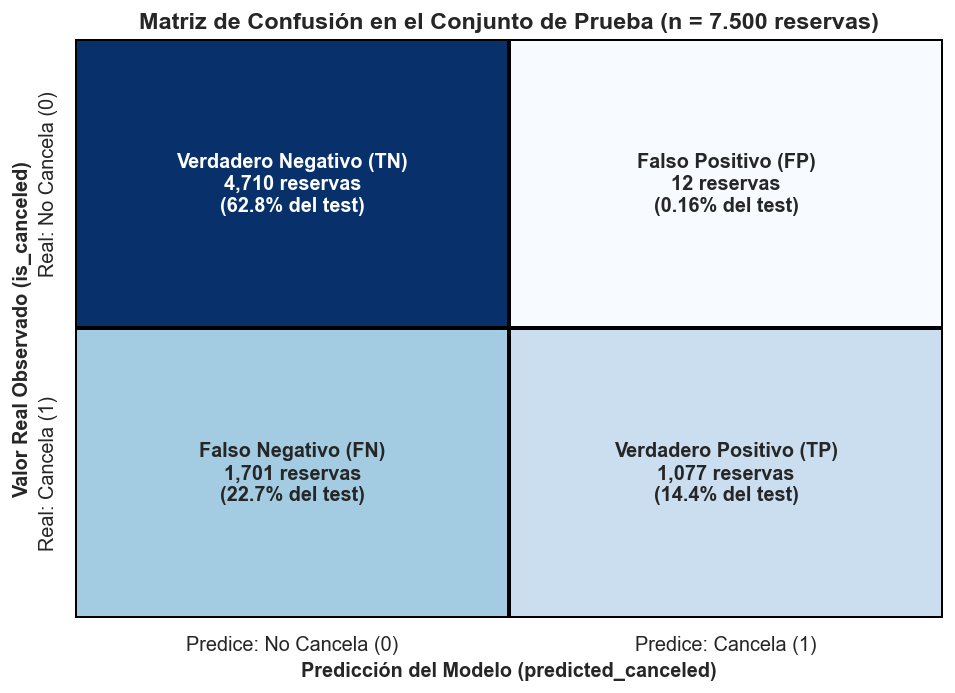

In [6]:
# Visualización gráfica de la Matriz de Confusión con etiquetas claras de TN, FP, FN y TP
fig, ax = plt.subplots(figsize=(7.5, 5.5))

etiquetas_celdas = np.array([
    [f"Verdadero Negativo (TN)\n{tn:,} reservas\n({tn/len(y_test)*100:.1f}% del test)",
     f"Falso Positivo (FP)\n{fp:,} reservas\n({fp/len(y_test)*100:.2f}% del test)"],
    [f"Falso Negativo (FN)\n{fn:,} reservas\n({fn/len(y_test)*100:.1f}% del test)",
     f"Verdadero Positivo (TP)\n{tp:,} reservas\n({tp/len(y_test)*100:.1f}% del test)"]
])

sns.heatmap(
    cm,
    annot=etiquetas_celdas,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predice: No Cancela (0)", "Predice: Cancela (1)"],
    yticklabels=["Real: No Cancela (0)", "Real: Cancela (1)"],
    annot_kws={"size": 11, "weight": "bold"},
    linewidths=2,
    linecolor="black",
    ax=ax
)

ax.set_title("Matriz de Confusión en el Conjunto de Prueba (n = 7.500 reservas)")
ax.set_xlabel("Predicción del Modelo (predicted_canceled)", fontsize=11, fontweight="bold")
ax.set_ylabel("Valor Real Observado (is_canceled)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### Lectura detallada de la Matriz de Confusión:
Sobre las **7.500 reservas** del conjunto de prueba (`4.722` realmente no canceladas y `2.778` realmente canceladas):
1. **Verdaderos Negativos (`TN = 4.710`):** El modelo identificó correctamente a `4.710` de las `4.722` reservas que no se cancelaron (acertó el **99,75%** de las estadías efectivas).
2. **Verdaderos Positivos (`TP = 1.077`):** El modelo detectó con éxito `1.077` reservas que efectivamente terminaron cancelándose.
3. **Falsos Positivos (`FP = 12`):** Apenas `12` reservas fueron clasificadas erróneamente como cancelaciones cuando en realidad los huéspedes sí se presentaron.
4. **Falsos Negativos (`FN = 1.701`):** El principal volumen de error del modelo se concentra aquí: `1.701` reservas que el modelo clasificó como "No Cancela (`0`)" terminaron cancelándose en la realidad.

---

## 5. Cálculo e Interpretación de las Métricas de Clasificación

Calculamos a continuación las cuatro métricas requeridas sobre el conjunto de prueba, verificando que las fórmulas matemáticas a partir de `TP`, `TN`, `FP` y `FN` coinciden exactamente con las funciones de `scikit-learn`:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad \text{F1-score} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

In [7]:
# Cálculo explícito y con scikit-learn de las 4 métricas de evaluación sobre el conjunto de prueba
accuracy_val = accuracy_score(y_test, y_pred_test)
precision_val = precision_score(y_test, y_pred_test)
recall_val = recall_score(y_test, y_pred_test)
f1_val = f1_score(y_test, y_pred_test)

tabla_metricas = pd.DataFrame({
    "Métrica": ["Accuracy (Exactitud global)", "Precision (Precisión positiva)", "Recall (Sensibilidad / Exhaustividad)", "F1-score (Media armónica)"],
    "Fórmula sobre la Matriz": [
        f"({tp} + {tn}) / 7500",
        f"{tp} / ({tp} + {fp})",
        f"{tp} / ({tp} + {fn})",
        f"2 * ({precision_val:.4f} * {recall_val:.4f}) / ({precision_val:.4f} + {recall_val:.4f})"
    ],
    "Valor Decimal": [round(accuracy_val, 4), round(precision_val, 4), round(recall_val, 4), round(f1_val, 4)],
    "Porcentaje (%)": [round(accuracy_val*100, 2), round(precision_val*100, 2), round(recall_val*100, 2), round(f1_val*100, 2)]
})

tabla_metricas

,Métrica,Fórmula sobre la Matriz,Valor Decimal,Porcentaje (%)
0,Accuracy (Exactitud global),(1077 + 4710) / 7500,0.7716,77.16
1,Precision (Precisión positiva),1077 / (1077 + 12),0.9890,98.90
2,Recall (Sensibilidad / Exhaustividad),1077 / (1077 + 1701),0.3877,38.77
3,F1-score (Media armónica),2 * (0.9890 * 0.3877) / (0.9890 + 0.3877),0.5570,55.70


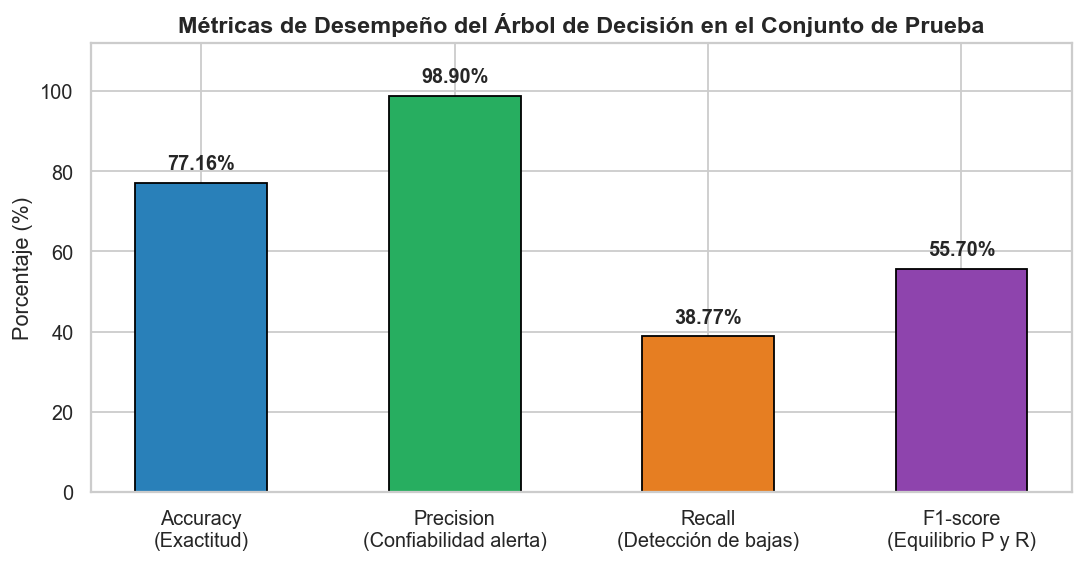

In [8]:
# Visualización comparativa de las 4 métricas de clasificación en el conjunto de prueba
fig, ax = plt.subplots(figsize=(8.5, 4.5))
nombres_m = ["Accuracy\n(Exactitud)", "Precision\n(Confiabilidad alerta)", "Recall\n(Detección de bajas)", "F1-score\n(Equilibrio P y R)"]
valores_m = [accuracy_val * 100, precision_val * 100, recall_val * 100, f1_val * 100]
colores_m = ["#2980b9", "#27ae60", "#e67e22", "#8e44ad"]

barras_m = ax.bar(nombres_m, valores_m, color=colores_m, edgecolor="black", width=0.52)
ax.set_title("Métricas de Desempeño del Árbol de Decisión en el Conjunto de Prueba")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, 112)

for b in barras_m:
    h = b.get_height()
    ax.annotate(
        f"{h:.2f}%",
        xy=(b.get_x() + b.get_width() / 2, h),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center", va="bottom", fontweight="bold", fontsize=11
    )

plt.tight_layout()
plt.show()

### Interpretación individual de cada métrica sobre el comportamiento del modelo:

1. **`Accuracy = 0.7716` (77,16%):**
   * *¿Qué informa?* Indica la proporción global de aciertos del modelo sobre el total de reservas evaluadas (`5.787` aciertos entre `TP` y `TN` sobre `7.500` casos de prueba).
   * *Lectura crítica:* Supera ampliamente la tasa base de la clase mayoritaria (si un modelo trivial predijera siempre "No Cancela", acertaría el 62,96%). Sin embargo, mirar únicamente el 77,16% de `Accuracy` resulta insuficiente porque oculta una fuerte asimetría entre la capacidad para acertar casos negativos y la capacidad para detectar todas las cancelaciones reales.
2. **`Precision = 0.9890` (98,90%):**
   * *¿Qué informa?* Responde a la pregunta: *cuando el modelo predice que una reserva se va a cancelar, ¿qué proporción de esas alertas es realmente una cancelación?* De las `1.089` reservas que el modelo marcó como cancelación (`1.077 TP + 12 FP`), **acertó en el 98,90% de los casos**.
   * *Lectura crítica:* El modelo es **extremadamente preciso y conservador** al emitir una alerta positiva: prácticamente no genera falsas alarmas (`FP = 12`), porque solo clasifica como `1` aquellas reservas con señales fortísimas de baja (como depósito `Non Refund` o clientes con antecedentes de cancelación previa y alta anticipación).
3. **`Recall = 0.3877` (38,77%):**
   * *¿Qué informa?* Responde a la pregunta: *de todas las reservas que realmente se cancelaron en el conjunto de prueba (`2.778`), ¿qué proporción logró capturar el modelo?* El clasificador detectó `1.077` de las `2.778` cancelaciones reales (**38,77%**), dejando sin detectar el **61,23% restante (`1.701 FN`)**.
   * *Lectura crítica:* Es el punto más débil del árbol de profundidad 3: la mayoría de las cancelaciones que ocurren en reservas comunes (modalidad `No Deposit` y sin antecedentes previos) quedan en nodos hoja donde la probabilidad de cancelación ronda el 36,9%, lo cual está por debajo del umbral estándar del 50% y hace que el árbol las clasifique como `0`.
4. **`F1-score = 0.5570` (55,70%):**
   * *¿Qué informa?* Es la media armónica entre `Precision` y `Recall`. A diferencia de un promedio simple (que daría 68,8%), el `F1-score` penaliza el desequilibrio cuando una de las dos métricas es baja.
   * *Lectura crítica:* El valor de **55,70%** sintetiza con realismo que, si bien el modelo posee una confiabilidad casi perfecta cuando alerta (`Precision = 98,90%`), su sensibilidad moderada-baja (`Recall = 38,77%`) limita su cobertura global sobre la clase positiva.

---

## 6. Interpretación de los Errores en el Contexto de las Reservas Hoteleras

### 6.1. ¿Qué significa cada tipo de error en el negocio hotelero?

| Tipo de Error | Cantidad en Test | Significado en el Problema | Consecuencias Operativas y Comerciales para el Hotel |
|---|---:|---|---|
| **Falso Positivo (`FP`)** | **12 casos** (0,16% del test) | El modelo **predice que la reserva se cancelará (`1`)**, pero el huésped **NO cancela y se presenta al *check-in* (`0`)**. | • Si el hotel utiliza la predicción para hacer **sobreventa (*overbooking*)** y revende esa habitación, se encontrará con dos clientes para una misma plaza (*walk-in conflict*), debiendo reubicar al huésped en otro hotel a costo propio, pagar compensaciones y sufrir **daño reputacional**.<br/>• Si la usa para exigir prepago agresivo o cancelar preventivamente la reserva, puede molestar y perder a un cliente fiel. |
| **Falso Negativo (`FN`)** | **1.701 casos** (22,68% del test) | El modelo **predice que la reserva se mantendrá firme (`0`)**, pero el cliente **finalmente CANCELA la estadía (`1`)**. | • El hotel confía en esa ocupación proyectada y no toma recaudos comerciales.<br/>• Cuando la cancelación ocurre cerca de la fecha de arribo (o como *No-Show*), la **habitación queda vacía** (capacidad perecedera no vendida), generando **pérdida directa de ingresos por habitación (`ADR` + consumos)** y desaprovechamiento de campañas de reconfirmación temprana. |

### 6.2. Análisis complementario en SQL: ¿Dónde se concentran los errores del modelo?
Consultamos mediante **SQL** cómo se distribuyen los Falsos Negativos (`FN`) y Falsos Positivos (`FP`) según el tipo de hotel y el segmento de mercado:

In [9]:
# Consulta SQL: Desglose de aciertos y errores (FP y FN) según Tipo de Hotel y Segmento de Mercado
errores_por_segmento = con.sql("""
SELECT
    hotel,
    market_segment,
    COUNT(*) AS casos_test,
    SUM(CASE WHEN is_canceled = 1 AND predicted_canceled = 1 THEN 1 ELSE 0 END) AS TP,
    SUM(CASE WHEN is_canceled = 0 AND predicted_canceled = 0 THEN 1 ELSE 0 END) AS TN,
    SUM(CASE WHEN is_canceled = 0 AND predicted_canceled = 1 THEN 1 ELSE 0 END) AS FP_falsa_alarma,
    SUM(CASE WHEN is_canceled = 1 AND predicted_canceled = 0 THEN 1 ELSE 0 END) AS FN_no_detectada,
    ROUND(AVG(CASE WHEN is_canceled <> predicted_canceled THEN 1.0 ELSE 0.0 END) * 100, 2) AS tasa_error_pct
FROM evaluacion_modelo
GROUP BY hotel, market_segment
HAVING COUNT(*) >= 50
ORDER BY FN_no_detectada DESC
""").df()

errores_por_segmento

,hotel,market_segment,casos_test,TP,TN,FP_falsa_alarma,FN_no_detectada,tasa_error_pct
0,City Hotel,Online TA,2416,28.0,1529.0,0.0,859.0,35.55
1,Resort Hotel,Online TA,1117,10.0,733.0,1.0,373.0,33.48
2,City Hotel,Offline TA/TO,1040,353.0,567.0,1.0,119.0,11.54
3,City Hotel,Groups,867,520.0,279.0,0.0,68.0,7.84
4,City Hotel,Direct,401,7.0,327.0,0.0,67.0,16.71
5,Resort Hotel,Groups,382,118.0,203.0,2.0,59.0,15.97
6,Resort Hotel,Offline TA/TO,451,17.0,382.0,0.0,52.0,11.53
7,Resort Hotel,Direct,425,2.0,370.0,3.0,50.0,12.47
8,Resort Hotel,Corporate,162,4.0,129.0,2.0,27.0,17.90
9,City Hotel,Corporate,174,18.0,138.0,3.0,15.0,10.34


### 6.3. ¿Cuál de los dos errores es especialmente relevante para la gestión hotelera? (Justificación)

En el contexto de este problema y a la luz de los resultados obtenidos, **el error especialmente relevante a atender es el Falso Negativo (`FN = 1.701 casos`)**, por dos razones fundamentales:

1. **Magnitud empírica y pérdida silenciosa de ingresos:**
   * En nuestro modelo actual, los Falsos Positivos son prácticamente inexistentes (`12` casos en `7.500` reservas), mientras que los **Falsos Negativos ascienden a `1.701` reservas** (concentradas sobre todo en `Online TA` del `City Hotel` con `885 FN` y del `Resort Hotel` con `384 FN`).
   * Cada Falso Negativo representa una reserva que la gerencia cree asegurada pero que se caerá. Considerando la estadía mediana de 3 noches y una tarifa mediana de ~\$96,30 por noche en reservas canceladas, no anticipar esas `1.701` bajas equivale a dejar expuestos cerca de **\$490.000 en ingresos brutos potenciales** en la muestra de prueba sin aplicar ninguna acción preventiva.
2. **Viabilidad de acciones preventivas de bajo costo ante la detección:**
   * Si el objetivo de la gestión hotelera es **implementar medidas preventivas no invasivas** (como enviar recordatorios automáticos de confirmación por WhatsApp/email 15 días antes, ofrecer un pequeño beneficio por confirmar la estadía o solicitar una tarjeta en garantía), el costo de un Falso Positivo es mínimo (un mensaje enviado a un cliente que igual iba a viajar), mientras que **el costo de un Falso Negativo es altísimo** (perder la venta de la habitación porque nadie gestionó el riesgo a tiempo).
   * *Matiz estratégico:* Únicamente si el hotel pretendiera utilizar el modelo para **revender automáticamente la habitación (*overbooking* duro)**, el **Falso Positivo (`FP`)** pasaría a ser el error más peligroso por el costo legal y reputacional de dejar a un huésped sin habitación. Precisamente en ese escenario específico de *overbooking*, la altísima `Precision` actual del modelo (**98,90%**, con solo `12 FP`) resulta una ventaja operativa notable.

---

## 7. Conclusión General: Utilidad, Respaldo Empírico y Limitaciones del Modelo

### 7.1. ¿Aporta el modelo información útil para anticipar cancelaciones?
**Sí, el modelo aporta información claramente útil como primer sistema de alerta temprana**, especialmente para identificar el núcleo duro de reservas con altísima propensión a cancelarse antes de que ocurra la fecha de *check-in*, superando en más de 14 puntos porcentuales la exactitud de una clasificación ingenua por clase mayoritaria.

### 7.2. ¿Qué aspectos de su desempeño respaldan esta conclusión?
1. **Sólida capacidad de generalización sin sobreajuste:** La exactitud en el conjunto de prueba (**`Accuracy = 77,16%`** sobre `7.500` casos no vistos) se mantiene en el mismo nivel que en el conjunto de entrenamiento (**`76,50%`** sobre `17.500` casos), probando que las reglas aprendidas son consistentes.
2. **Confiabilidad casi perfecta en sus alertas positivas (`Precision = 98,90%`):** De las `1.089` reservas que el modelo señala como futuras cancelaciones en el conjunto de prueba, `1.077` se cancelan realmente (`TP = 1.077` vs. apenas `FP = 12`). Esto permite a la gerencia actuar con altísima seguridad sobre el segmento alertado.
3. **Interpretabilidad transparente:** Al tratarse de un árbol de decisión de 3 niveles, la gerencia puede auditar exactamente por qué se activa cada predicción (`deposit_type`, `previous_cancellations`, `lead_time` y `total_of_special_requests`).

### 7.3. ¿Qué limitaciones deben considerarse antes de utilizar sus predicciones para tomar decisiones?
1. **Sensibilidad moderada-baja (`Recall = 38,77%`) y alto volumen de Falsos Negativos (`FN = 1.701`):** El modelo detecta menos de 4 de cada 10 cancelaciones reales. En particular, en reservas de agencias online (`Online TA`) sin depósito previo (`No Deposit`), el árbol asigna probabilidades cercanas a `0.37` (por debajo del umbral de `0.50`), dejando pasar muchas cancelaciones sin alertar. Antes de decidir, sería recomendable utilizar las **probabilidades estimadas** (por ejemplo, creando una franja de "riesgo moderado" entre `0.30` y `0.50`) en lugar de quedarse solo con la etiqueta binaria `0/1`.
2. **Dependencia de la variable `deposit_type` (*Non Refund*) y posible sesgo operativo:** Como advertimos en el EDA (Entrega 4), gran parte del poder discriminante inicial del árbol proviene de `deposit_type_Non Refund`. Debe verificarse con el área administrativa del hotel que esa etiqueta esté disponible genuinamente al momento de crear la reserva y no sea producto de una actualización contable posterior a la baja (*data leakage*).
3. **Omisión de factores contextuales y ausencia de causalidad:** El modelo no observa variables externas (clima, precios de la competencia, feriados o antelación exacta de aviso de la baja), y sus reglas reflejan **asociaciones históricas, no relaciones de causa-efecto**. Por ejemplo, que `Online TA` o un `lead_time` alto eleven la probabilidad de cancelación no significa que bloquear las ventas anticipadas vaya a aumentar la rentabilidad neta del hotel.

In [10]:
# Cierre limpio de la conexión a DuckDB
con.close()
print("🔒 Conexión a DuckDB cerrada correctamente. Evaluación de la Entrega 6 completada con éxito.")

🔒 Conexión a DuckDB cerrada correctamente. Evaluación de la Entrega 6 completada con éxito.
